In [2]:
# ============================================================
# Step 1: Verify the Python Environment and Required Packages
# ============================================================
# Purpose:
# 1. Confirm that the Python environment is working correctly.
# 2. Confirm that pandas is available for data processing.
# 3. Confirm that pyodbc is available for connecting to CGMS SQL Server.

# Import pandas for data loading, cleaning, and analysis
import pandas as pd



# Display package versions to confirm the environment setup
print("Python environment is ready!")
print("Pandas version:", pd.__version__)


Python environment is ready!
Pandas version: 2.3.3


In [3]:
# ============================================================
# Step 2: Install the SQL Server Connection Package
# ============================================================
# pyodbc is required to connect Python to the CGMS SQL Server database.
# %pip installs the package into the Python environment used by this notebook.

%pip install pyodbc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# ============================================================
# Step 3: Verify the Database Connection Package
# ============================================================
# Import pyodbc and confirm that the installation was successful.

import pyodbc

print("pyodbc is ready!")
print("pyodbc version:", pyodbc.version)

pyodbc is ready!
pyodbc version: 5.3.0


In [5]:
# ============================================================
# Step 4: Check Available SQL Server ODBC Drivers
# ============================================================
# Purpose:
# Check which ODBC drivers are installed on the local computer.
# Python will use one of these drivers to connect to the CGMS SQL Server.

import pyodbc

drivers = pyodbc.drivers()

print("Available ODBC drivers:")
for driver in drivers:
    print("-", driver)

Available ODBC drivers:
- SQL Server


In [6]:
# ============================================================
# Step 5: Connect to the CGMS SQL Server Database
# ============================================================
# Purpose:
# 1. Connect Python to the CGMS_MDL local replica.
# 2. Use Windows Authentication / SSO instead of username and password.
# 3. Verify that the database connection works successfully.

import pyodbc

# Database connection parameters
server = "he-db.mdl.ccm.conti.de"
database = "CGMS_MDL"

# Build the connection string using Windows Authentication
# No username or password is required because SSO is enabled.
connection_string = (
    "DRIVER={SQL Server};"
    f"SERVER={server},1433;"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
)

# Try to connect to the CGMS SQL Server
try:
    conn = pyodbc.connect(connection_string)

    print("Database connection successful!")
    print("Server:", server)
    print("Database:", database)
    print("Authentication: Windows Authentication / SSO")

except pyodbc.Error as error:
    print("Database connection failed.")
    print("Error:", error)

Database connection successful!
Server: he-db.mdl.ccm.conti.de
Database: CGMS_MDL
Authentication: Windows Authentication / SSO


In [7]:
# ============================================================
# Step 6: Test Data Extraction from CGMS
# ============================================================
# Purpose:
# 1. Verify that Python can execute SQL queries on CGMS_MDL.
# 2. Load a small sample of production order data into pandas.
# 3. Confirm that the database connection and data extraction work correctly.

# Test query: retrieve a small sample from the Orders table
test_query = """
SELECT TOP 10 *
FROM [Orders]
"""

# Execute the SQL query and load the result into a pandas DataFrame
df_test = pd.read_sql(test_query, conn)

# Display the first rows
print("Data extraction successful!")
print("Number of rows:", len(df_test))
print("Number of columns:", len(df_test.columns))

df_test.head()

Data extraction successful!

C:\Users\Wangw3\AppData\Local\Temp\ipykernel_21164\1142827995.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_test = pd.read_sql(test_query, conn)



Number of rows: 10
Number of columns: 73


,OrderID,OrderIDLinked,OrderIDParent,OrderTypeID,WorkCenterID,RecipeID,MaterialMasterID,CarrierTypeID,OrderStatusID,PlantCode,...,OrderIDPaired,ExtTerminated,OrderIDCoupled,WorkCenterNameCoupled,MaterialMasterIDCoupled,OrderIDLeading,WorkCenterNameLeading,MaterialMasterIDLeading,PhaseInOut,IsGAPOrder
0,0100305432,None,None,None,651,119926,992540000200,None,12,9200,...,None,False,None,None,None,None,None,None,,False
1,0100305433,None,None,None,651,119926,992540000200,None,12,9200,...,None,False,None,None,None,None,None,None,,False
2,0100305435,None,None,None,651,119926,992540000200,None,12,9200,...,None,False,None,None,None,None,None,None,,False
3,0100305438,None,None,None,651,119926,992540000200,None,11,9200,...,None,False,None,None,None,None,None,None,,False
4,0100305480,None,None,None,651,119928,992540001700,None,12,9200,...,None,False,None,None,None,None,None,None,,False


In [8]:
# ============================================================
# Step 7: Extract Production Data for TB Capacity Analysis
# ============================================================
# Purpose:
# 1. Extract TB production order data from CGMS_MDL.
# 2. Combine production orders with Work Center, Production Version,
#    and Recipe information.
# 3. Load the SQL query result into a pandas DataFrame.
# 4. Create the main dataset for the following capacity analysis.

# Paste the validated SQL query from DBeaver between the triple quotes
query = """

SELECT
    -- ============================================================
    -- 1. Original fields from Orders
    -- ============================================================

    a.[OrderID],
    a.[OrderIDLinked],
    a.[WorkCenterID],
    a.[RecipeID],
    a.[MaterialMasterID],
    a.[Comment],

    -- Planned quantity
    a.[QuantitySet] AS PlannedQuantity,

    -- Actual finished quantity
    a.[QuantityDone],

    a.[ShiftNumber],
    a.[ShiftDate],
    a.[ActualStartTime],
    a.[ActualEndTime],
    a.[PlannedStartTime],
    a.[PlannedEndTime],
    a.[ProdVersion],
    a.[ProdVariant],
    a.[DestinationInfo],
    a.[ETOFlag],
    a.[PLCOrderNumber],
    a.[StatusUpdatedOn],
    a.[IsParent],
    a.[CreatedByCGMS],
    a.[InsertedOn],
    a.[UpdatedOn],
    a.[UserIDInsertedBy],
    a.[ExtTerminated],
    a.[OrderIDCoupled],
    a.[WorkCenterNameCoupled],
    a.[MaterialMasterIDCoupled],
    a.[PhaseInOut],
    a.[IsGAPOrder],


    -- ============================================================
    -- 2. Actual production duration
    --
    -- Formula:
    -- ActualEndTime - ActualStartTime
    --
    -- Unit: Seconds
    -- ============================================================

    DATEDIFF_BIG(
        SECOND,
        a.[ActualStartTime],
        a.[ActualEndTime]
    ) AS ActualProcessingTime,


    -- ============================================================
    -- 3. Actual production time per tire
    --
    -- Formula:
    -- (ActualEndTime - ActualStartTime) / QuantityDone
    --
    -- Unit: Seconds per tire
    -- ============================================================

    CASE
        WHEN a.[QuantityDone] > 0
        THEN
            CAST(
                DATEDIFF_BIG(
                    SECOND,
                    a.[ActualStartTime],
                    a.[ActualEndTime]
                ) AS DECIMAL(18, 4)
            )
            /
            CAST(
                a.[QuantityDone] AS DECIMAL(18, 4)
            )
        ELSE NULL
    END AS ActualTimePerTire,


    -- ============================================================
    -- 4. Descriptive information
    -- ============================================================

    -- Order status
    b.[GlobalName] AS OrderStatus,

    -- Work center name
    c.[Name] AS WorkCenterName,


    -- ============================================================
    -- 5. IE standard data from ProductionVersion
    --
    -- Matching:
    -- MaterialMasterID + WorkCenterID
    -- ============================================================

    d.[CycleTimePieces] AS CycleTimePieces,

    -- IE standard cycle time per 100 tires
    d.[CycleTime] AS IEStandardCycleTimePer100Tire,

    -- IE cycle time tolerance per 100 tires
    d.[CycleTimeTolerance] AS CycleTimeTolerancePer100Tire,

    -- IE standard total time per tire
    d.[TotalTime] AS IEStandardTotalTimePerTire,

    -- IE standard setup time per 100 tires
    d.[StandardSetupTime] AS StandardSetupTimePer100Tire,


    -- ============================================================
    -- 6. Operator information from UserLogin
    -- ============================================================

    -- Internal User ID
    ul.[UserID] AS OperatorUserID,

    -- Employee number
    ul.[EmployeeNumber] AS OperatorEmployeeNumber,

    -- Operator login start
    ul.[StartDate] AS OperatorStartDate,

    -- Operator login end
    ul.[EndDate] AS OperatorEndDate,

    -- Team leader flag
    ul.[IsTeamLeader] AS OperatorIsTeamLeader,

    -- Operator role
    ul.[OperatorWorkcenterRoleCatalogID]
        AS OperatorWorkcenterRoleCatalogID,


    -- ============================================================
    -- 7. Operator overlap start
    --
    -- Take later timestamp between:
    -- ActualStartTime and Operator StartDate
    -- ============================================================

    CASE
        WHEN ul.[UserID] IS NULL
            THEN NULL

        WHEN ul.[StartDate] > a.[ActualStartTime]
            THEN ul.[StartDate]

        ELSE a.[ActualStartTime]

    END AS OperatorOverlapStart,


    -- ============================================================
    -- 8. Operator overlap end
    --
    -- Take earlier timestamp between:
    -- ActualEndTime and Operator EndDate
    -- ============================================================

    CASE
        WHEN ul.[UserID] IS NULL
            THEN NULL

        WHEN ul.[EndDate] < a.[ActualEndTime]
            THEN ul.[EndDate]

        ELSE a.[ActualEndTime]

    END AS OperatorOverlapEnd,


    -- ============================================================
    -- 9. Operator overlap duration
    --
    -- Unit: Seconds
    -- ============================================================

    CASE
        WHEN ul.[UserID] IS NULL
            THEN NULL

        ELSE
            DATEDIFF_BIG(
                SECOND,

                CASE
                    WHEN ul.[StartDate] > a.[ActualStartTime]
                        THEN ul.[StartDate]
                    ELSE a.[ActualStartTime]
                END,

                CASE
                    WHEN ul.[EndDate] < a.[ActualEndTime]
                        THEN ul.[EndDate]
                    ELSE a.[ActualEndTime]
                END
            )

    END AS OperatorOverlapSeconds,


    -- ============================================================
    -- 10. Operator Coverage Ratio
    --
    -- Formula:
    -- OperatorOverlapSeconds / ActualProcessingTime
    --
    -- Examples:
    -- 1.00 = Operator covers 100% of Order duration
    -- 0.80 = Operator covers 80%
    -- 0.50 = Operator covers 50%
    -- 0.05 = Operator covers 5%
    -- ============================================================

    CASE
        WHEN ul.[UserID] IS NULL
            THEN NULL

        ELSE
            CAST(
                DATEDIFF_BIG(
                    SECOND,

                    CASE
                        WHEN ul.[StartDate] > a.[ActualStartTime]
                            THEN ul.[StartDate]
                        ELSE a.[ActualStartTime]
                    END,

                    CASE
                        WHEN ul.[EndDate] < a.[ActualEndTime]
                            THEN ul.[EndDate]
                        ELSE a.[ActualEndTime]
                    END

                ) AS DECIMAL(18, 4)
            )
            /
            NULLIF(
                CAST(
                    DATEDIFF_BIG(
                        SECOND,
                        a.[ActualStartTime],
                        a.[ActualEndTime]
                    ) AS DECIMAL(18, 4)
                ),
                0
            )

    END AS OperatorCoverageRatio


-- ================================================================
-- 11. Main table: Orders
-- ================================================================

FROM [Orders] a WITH (NOLOCK)


-- ================================================================
-- 12. Join OrderStatus
-- ================================================================

INNER JOIN [OrderStatus] b WITH (NOLOCK)
    ON a.[OrderStatusID] = b.[OrderStatusID]


-- ================================================================
-- 13. Join WorkCenter
-- ================================================================

INNER JOIN [WorkCenter] c WITH (NOLOCK)
    ON a.[WorkCenterID] = c.[WorkCenterID]


-- ================================================================
-- 14. Join ProductionVersion
--
-- Match using:
-- MaterialMasterID + WorkCenterID
-- ================================================================

LEFT JOIN [ProductionVersion] d WITH (NOLOCK)
    ON a.[MaterialMasterID] = d.[MaterialMasterID]
    AND a.[WorkCenterID] = d.[WorkCenterID]


-- ================================================================
-- 15. Join UserLogin
--
-- Operator / Order matching logic:
--
-- 1. Same WorkCenterID
-- 2. Operator StartDate < Order ActualEndTime
-- 3. Operator EndDate > Order ActualStartTime
--
-- Therefore:
-- Operator login period overlaps with Order production period.
--
-- LEFT JOIN:
-- Keep Order even when no valid Operator record is found.
-- ================================================================

LEFT JOIN [UserLogin] ul WITH (NOLOCK)

    -- Same WorkCenter
    ON a.[WorkCenterID] = ul.[WorkCenterID]

    -- Operator starts before the Order finishes
    AND ul.[StartDate] < a.[ActualEndTime]

    -- Operator ends after the Order starts
    AND ul.[EndDate] > a.[ActualStartTime]

    -- Only use completed UserLogin sessions
    AND ul.[EndDate] IS NOT NULL


-- ================================================================
-- 16. Data filters
-- ================================================================

WHERE c.[Name] LIKE 'TB%'

    -- Actual production start must exist
    AND a.[ActualStartTime] IS NOT NULL

    -- Actual production end must exist
    AND a.[ActualEndTime] IS NOT NULL

    -- End time cannot be before start time
    AND a.[ActualEndTime] >= a.[ActualStartTime]

    -- Only include QuantityDone > 0
    AND a.[QuantityDone] > 0

    -- Only include completed Orders
    AND b.[GlobalName] = 'Completed'

    -- Only retain current MaterialMasterID scope
    AND a.[MaterialMasterID] LIKE '99268%'

    -- Exclude CWM Orders
    AND a.[OrderID] NOT LIKE 'CWM%'


-- ================================================================
-- 17. Sort newest inserted Orders first
-- ================================================================

ORDER BY a.[InsertedOn] DESC;


"""

# Execute the SQL query and load the result into a pandas DataFrame
df_capacity = pd.read_sql(query, conn)

# Check the extracted dataset
print("Data extraction completed!")
print("Number of rows:", len(df_capacity))
print("Number of columns:", len(df_capacity.columns))

# Preview the first 5 records
df_capacity.head()

C:\Users\Wangw3\AppData\Local\Temp\ipykernel_21164\911673561.py:380: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_capacity = pd.read_sql(query, conn)


Data extraction completed!
Number of rows: 61343
Number of columns: 50


,OrderID,OrderIDLinked,WorkCenterID,RecipeID,MaterialMasterID,Comment,PlannedQuantity,QuantityDone,ShiftNumber,ShiftDate,...,OperatorUserID,OperatorEmployeeNumber,OperatorStartDate,OperatorEndDate,OperatorIsTeamLeader,OperatorWorkcenterRoleCatalogID,OperatorOverlapStart,OperatorOverlapEnd,OperatorOverlapSeconds,OperatorCoverageRatio
0,0131060447,0131060858,518,148299,992680941200,1: N03201-D111T,110.0,120.0,02,2026-11-04,...,559.0,120888,2026-11-04 08:03:45.300,2026-11-04 15:58:30.403,True,None,2026-11-04 14:52:10.507,2026-11-04 15:58:30.403,3980.0,0.499749
1,0131060447,0131060858,518,148299,992680941200,1: N03201-D111T,110.0,120.0,02,2026-11-04,...,635.0,151804,2026-11-04 15:58:29.990,2026-11-04 23:54:16.483,True,None,2026-11-04 15:58:29.990,2026-11-04 17:04:54.357,3985.0,0.500377
2,0130898022,0130898120,524,164255,992681040900,1: N03303-D222V,50.0,39.0,02,2026-11-04,...,1388.0,151666,2026-11-04 14:37:19.313,2026-11-04 14:45:45.587,True,None,2026-11-04 14:37:19.313,2026-11-04 14:37:47.567,28.0,0.009773
3,0130898022,0130898120,524,164255,992681040900,1: N03303-D222V,50.0,39.0,02,2026-11-04,...,627.0,151747,2026-11-04 11:03:26.693,2026-11-04 14:37:17.407,True,None,2026-11-04 13:50:02.530,2026-11-04 14:37:17.407,2835.0,0.989529
4,0131053632,0131051326,517,169109,992681055800,1: N03303-D111T PO: Last lot PO,10.0,11.0,03,2026-11-04,...,1000.0,223791,2026-11-04 15:59:51.593,2026-11-04 23:50:22.113,True,None,2026-11-04 19:49:34.627,2026-11-04 20:13:38.367,1444.0,1.000000


In [9]:
# ============================================================
# Step 8: Initial Data Quality Check
# ============================================================
# Purpose:
# 1. Check the overall structure of the extracted dataset.
# 2. Review all column names and data types.
# 3. Check missing values across the full dataset.
# 4. Check duplicate rows and unique OrderIDs.
# 5. Understand the dataset before selecting analysis features.
# ============================================================


# ============================================================
# 8.1 Dataset dimensions
# ============================================================

print("Dataset shape:", df_capacity.shape)
print("Number of rows:", df_capacity.shape[0])
print("Number of columns:", df_capacity.shape[1])


# ============================================================
# 8.2 Display all column names
# ============================================================

print("\nColumns:")

for column in df_capacity.columns:
    print("-", column)


# ============================================================
# 8.3 Check data types
# ============================================================

print("\nData types:")

print(df_capacity.dtypes)


# ============================================================
# 8.4 Check missing values for ALL columns
# ============================================================
# Do not define key columns yet.
# First inspect missing values across the whole dataset.

missing_summary = pd.DataFrame({
    "MissingCount": df_capacity.isnull().sum(),
    "MissingPercent": (
        df_capacity.isnull().mean() * 100
    ).round(2)
})

missing_summary = (
    missing_summary
    .sort_values(
        "MissingPercent",
        ascending=False
    )
)

print("\nMissing values summary:")

display(missing_summary)


# ============================================================
# 8.5 Check completely duplicated rows
# ============================================================

duplicate_rows = df_capacity.duplicated().sum()

print("\nCompletely duplicated rows:", duplicate_rows)


# ============================================================
# 8.6 Check OrderID uniqueness
# ============================================================
# Important:
# One OrderID may appear multiple times because one production
# order can overlap with multiple Operator login records.

print("\nOrderID check:")

print("Total rows:", len(df_capacity))

print(
    "Unique OrderIDs:",
    df_capacity["OrderID"].nunique()
)

print(
    "Rows above unique OrderIDs:",
    len(df_capacity)
    - df_capacity["OrderID"].nunique()
)


# ============================================================
# 8.7 Preview the dataset
# ============================================================

print("\nDataset preview:")

display(df_capacity.head())

Dataset shape: (61343, 50)
Number of rows: 61343
Number of columns: 50

Columns:
- OrderID
- OrderIDLinked
- WorkCenterID
- RecipeID
- MaterialMasterID
- Comment
- PlannedQuantity
- QuantityDone
- ShiftNumber
- ShiftDate
- ActualStartTime
- ActualEndTime
- PlannedStartTime
- PlannedEndTime
- ProdVersion
- ProdVariant
- DestinationInfo
- ETOFlag
- PLCOrderNumber
- StatusUpdatedOn
- IsParent
- CreatedByCGMS
- InsertedOn
- UpdatedOn
- UserIDInsertedBy
- ExtTerminated
- OrderIDCoupled
- WorkCenterNameCoupled
- MaterialMasterIDCoupled
- PhaseInOut
- IsGAPOrder
- ActualProcessingTime
- ActualTimePerTire
- OrderStatus
- WorkCenterName
- CycleTimePieces
- IEStandardCycleTimePer100Tire
- CycleTimeTolerancePer100Tire
- IEStandardTotalTimePerTire
- StandardSetupTimePer100Tire
- OperatorUserID
- OperatorEmployeeNumber
- OperatorStartDate
- OperatorEndDate
- OperatorIsTeamLeader
- OperatorWorkcenterRoleCatalogID
- OperatorOverlapStart
- OperatorOverlapEnd
- OperatorOverlapSeconds
- OperatorCoverage

,MissingCount,MissingPercent
OperatorWorkcenterRoleCatalogID,61343,100.00
CreatedByCGMS,61343,100.00
OperatorIsTeamLeader,23065,37.60
OperatorEmployeeNumber,23065,37.60
IsParent,9718,15.84
UserIDInsertedBy,9718,15.84
OperatorStartDate,2704,4.41
OperatorUserID,2704,4.41
OperatorOverlapEnd,2704,4.41
OperatorOverlapStart,2704,4.41



Completely duplicated rows: 0

OrderID check:
Total rows: 61343
Unique OrderIDs: 23312
Rows above unique OrderIDs: 38031

Dataset preview:


,OrderID,OrderIDLinked,WorkCenterID,RecipeID,MaterialMasterID,Comment,PlannedQuantity,QuantityDone,ShiftNumber,ShiftDate,...,OperatorUserID,OperatorEmployeeNumber,OperatorStartDate,OperatorEndDate,OperatorIsTeamLeader,OperatorWorkcenterRoleCatalogID,OperatorOverlapStart,OperatorOverlapEnd,OperatorOverlapSeconds,OperatorCoverageRatio
0,0131060447,0131060858,518,148299,992680941200,1: N03201-D111T,110.0,120.0,02,2026-11-04,...,559.0,120888,2026-11-04 08:03:45.300,2026-11-04 15:58:30.403,True,None,2026-11-04 14:52:10.507,2026-11-04 15:58:30.403,3980.0,0.499749
1,0131060447,0131060858,518,148299,992680941200,1: N03201-D111T,110.0,120.0,02,2026-11-04,...,635.0,151804,2026-11-04 15:58:29.990,2026-11-04 23:54:16.483,True,None,2026-11-04 15:58:29.990,2026-11-04 17:04:54.357,3985.0,0.500377
2,0130898022,0130898120,524,164255,992681040900,1: N03303-D222V,50.0,39.0,02,2026-11-04,...,1388.0,151666,2026-11-04 14:37:19.313,2026-11-04 14:45:45.587,True,None,2026-11-04 14:37:19.313,2026-11-04 14:37:47.567,28.0,0.009773
3,0130898022,0130898120,524,164255,992681040900,1: N03303-D222V,50.0,39.0,02,2026-11-04,...,627.0,151747,2026-11-04 11:03:26.693,2026-11-04 14:37:17.407,True,None,2026-11-04 13:50:02.530,2026-11-04 14:37:17.407,2835.0,0.989529
4,0131053632,0131051326,517,169109,992681055800,1: N03303-D111T PO: Last lot PO,10.0,11.0,03,2026-11-04,...,1000.0,223791,2026-11-04 15:59:51.593,2026-11-04 23:50:22.113,True,None,2026-11-04 19:49:34.627,2026-11-04 20:13:38.367,1444.0,1.000000


In [10]:
# ============================================================
# Step 9: Check Data Granularity and Order Duplication
# ============================================================
# Purpose:
# 1. Check whether one OrderID appears multiple times.
# 2. Understand how many rows exist for each OrderID.
# 3. Check whether duplicated OrderIDs are caused by multiple Operators.
# 4. Keep the original data unchanged at this stage.
# ============================================================


# ============================================================
# 9.1 Basic OrderID statistics
# ============================================================

total_rows = len(df_capacity)
unique_orders = df_capacity["OrderID"].nunique()
duplicated_order_rows = total_rows - unique_orders

print("Total rows:", total_rows)
print("Unique OrderIDs:", unique_orders)
print("Additional rows due to repeated OrderIDs:", duplicated_order_rows)


# ============================================================
# 9.2 Count number of rows per OrderID
# ============================================================

order_row_count = (
    df_capacity
    .groupby("OrderID")
    .size()
    .reset_index(name="RowCount")
    .sort_values("RowCount", ascending=False)
)

print("\nOrderID row count summary:")
display(order_row_count.head(20))


# ============================================================
# 9.3 Distribution of number of rows per Order
# ============================================================

order_row_distribution = (
    order_row_count["RowCount"]
    .value_counts()
    .sort_index()
    .reset_index()
)

order_row_distribution.columns = [
    "RowsPerOrder",
    "NumberOfOrders"
]

print("\nDistribution of rows per Order:")
display(order_row_distribution)


# ============================================================
# 9.4 Check number of Operators per Order
# ============================================================
# Since Orders were joined with UserLogin using WorkCenterID
# and time overlap, one Order may legitimately have multiple
# Operator records.
# ============================================================

operator_per_order = (
    df_capacity
    .groupby("OrderID")
    .agg(
        RowCount=("OrderID", "size"),
        UniqueOperatorCount=("OperatorUserID", "nunique"),
        MaxOperatorCoverage=("OperatorCoverageRatio", "max"),
        TotalOperatorCoverage=("OperatorCoverageRatio", "sum")
    )
    .reset_index()
    .sort_values(
        ["UniqueOperatorCount", "RowCount"],
        ascending=False
    )
)

print("\nOperator records per Order:")
display(operator_per_order.head(20))


# ============================================================
# 9.5 Inspect Orders with multiple Operators
# ============================================================

multi_operator_orders = operator_per_order[
    operator_per_order["UniqueOperatorCount"] > 1
]

print(
    "\nOrders with more than one Operator:",
    len(multi_operator_orders)
)

print(
    "Share of Orders with more than one Operator:",
    round(
        len(multi_operator_orders) / unique_orders * 100,
        2
    ),
    "%"
)

display(multi_operator_orders.head(20))


# ============================================================
# 9.6 Inspect detailed records for several multi-Operator Orders
# ============================================================
# This helps confirm whether duplicated OrderIDs are genuinely
# caused by different Operator login periods.
# ============================================================

sample_order_ids = (
    multi_operator_orders["OrderID"]
    .head(5)
    .tolist()
)

sample_multi_operator_records = (
    df_capacity[
        df_capacity["OrderID"].isin(sample_order_ids)
    ]
    [
        [
            "OrderID",
            "WorkCenterName",
            "ActualStartTime",
            "ActualEndTime",
            "QuantityDone",
            "ActualTimePerTire",
            "OperatorUserID",
            "OperatorEmployeeNumber",
            "OperatorStartDate",
            "OperatorEndDate",
            "OperatorOverlapSeconds",
            "OperatorCoverageRatio"
        ]
    ]
    .sort_values(
        ["OrderID", "OperatorCoverageRatio"],
        ascending=[True, False]
    )
)

print("\nExample Orders with multiple Operator records:")
display(sample_multi_operator_records)

Total rows: 61343
Unique OrderIDs: 23312
Additional rows due to repeated OrderIDs: 38031

OrderID row count summary:


,OrderID,RowCount
6789,0116304746,28
18299,0126496465,27
7737,0117157148,21
22803,0130257175,21
8095,0117507461,21
16541,0125092721,20
19218,0127257107,20
12587,0120893065,20
9420,0118470920,19
13997,0122999134,18



Distribution of rows per Order:


,RowsPerOrder,NumberOfOrders
0,1,5022
1,2,8480
2,3,5059
3,4,2576
4,5,987
5,6,582
6,7,211
7,8,154
8,9,78
9,10,53



Operator records per Order:


,OrderID,RowCount,UniqueOperatorCount,MaxOperatorCoverage,TotalOperatorCoverage
18299,0126496465,27,9,0.066674,0.979801
6391,0116037287,16,8,0.454444,1.985741
9844,0118773729,12,8,0.491863,1.799951
12957,0121404057,9,8,1.000000,2.421884
12959,0121404069,18,7,1.000000,2.634427
10894,0119711250,13,7,1.000000,1.665884
12782,0121201051,13,7,0.686505,1.059157
9811,0118773364,11,7,0.558000,1.998773
14968,0123651335,10,7,1.000000,4.000736
9070,0118175498,8,7,1.000000,2.000149



Orders with more than one Operator: 18244
Share of Orders with more than one Operator: 78.26 %


,OrderID,RowCount,UniqueOperatorCount,MaxOperatorCoverage,TotalOperatorCoverage
18299,0126496465,27,9,0.066674,0.979801
6391,0116037287,16,8,0.454444,1.985741
9844,0118773729,12,8,0.491863,1.799951
12957,0121404057,9,8,1.000000,2.421884
12959,0121404069,18,7,1.000000,2.634427
10894,0119711250,13,7,1.000000,1.665884
12782,0121201051,13,7,0.686505,1.059157
9811,0118773364,11,7,0.558000,1.998773
14968,0123651335,10,7,1.000000,4.000736
9070,0118175498,8,7,1.000000,2.000149



Example Orders with multiple Operator records:


,OrderID,WorkCenterName,ActualStartTime,ActualEndTime,QuantityDone,ActualTimePerTire,OperatorUserID,OperatorEmployeeNumber,OperatorStartDate,OperatorEndDate,OperatorOverlapSeconds,OperatorCoverageRatio
51304,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,0.0,None,2026-09-10 21:13:46.197,2026-09-12 17:45:06.147,54850.0,0.454444
51300,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,0.0,None,2026-09-09 10:46:24.633,2026-09-10 16:46:36.323,49817.0,0.412744
51313,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1299.0,254539,2026-09-10 15:58:26.477,2026-09-10 23:55:09.110,28603.0,0.236982
51314,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1330.0,254617,2026-09-10 23:56:07.837,2026-09-11 07:32:38.190,27391.0,0.226940
51315,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1330.0,254617,2026-09-09 23:51:19.380,2026-09-10 08:01:05.590,18286.0,0.151503
...,...,...,...,...,...,...,...,...,...,...,...,...
14350,0126496465,TB244,2026-10-28 05:01:08.347,2026-11-02 09:31:37.367,121.0,3704.371901,1389.0,100205,2026-10-28 09:18:45.553,2026-10-28 09:35:19.523,994.0,0.002218
14351,0126496465,TB244,2026-10-28 05:01:08.347,2026-11-02 09:31:37.367,121.0,3704.371901,1389.0,100205,2026-10-28 11:52:14.950,2026-10-28 12:02:29.070,615.0,0.001372
14353,0126496465,TB244,2026-10-28 05:01:08.347,2026-11-02 09:31:37.367,121.0,3704.371901,1404.0,141282,2026-10-30 15:56:28.990,2026-10-30 16:00:05.610,217.0,0.000484
14374,0126496465,TB244,2026-10-28 05:01:08.347,2026-11-02 09:31:37.367,121.0,3704.371901,1147.0,244164,2026-10-28 07:55:50.470,2026-10-28 07:57:38.620,108.0,0.000241


In [11]:
# ============================================================
# Step 9.7: Inspect one Order and its Operator login sessions
# ============================================================
# Purpose:
# Check why one OrderID is matched with multiple UserLogin records.
# ============================================================

test_order = "0116037287"

order_operator_check = (
    df_capacity[
        df_capacity["OrderID"].astype(str) == test_order
    ]
    [
        [
            "OrderID",
            "WorkCenterName",
            "ActualStartTime",
            "ActualEndTime",
            "QuantityDone",
            "ActualTimePerTire",
            "OperatorUserID",
            "OperatorEmployeeNumber",
            "OperatorStartDate",
            "OperatorEndDate",
            "OperatorOverlapStart",
            "OperatorOverlapEnd",
            "OperatorOverlapSeconds",
            "OperatorCoverageRatio"
        ]
    ]
    .sort_values(
        [
            "OperatorUserID",
            "OperatorStartDate"
        ]
    )
)

display(order_operator_check)

,OrderID,WorkCenterName,ActualStartTime,ActualEndTime,QuantityDone,ActualTimePerTire,OperatorUserID,OperatorEmployeeNumber,OperatorStartDate,OperatorEndDate,OperatorOverlapStart,OperatorOverlapEnd,OperatorOverlapSeconds,OperatorCoverageRatio
51300,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,0.0,None,2026-09-09 10:46:24.633,2026-09-10 16:46:36.323,2026-09-10 02:56:19.803,2026-09-10 16:46:36.323,49817.0,0.412744
51302,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,0.0,None,2026-09-10 16:46:48.400,2026-09-10 20:57:23.353,2026-09-10 16:46:48.400,2026-09-10 20:57:23.353,15035.0,0.124568
51304,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,0.0,None,2026-09-10 21:13:46.197,2026-09-12 17:45:06.147,2026-09-10 21:13:46.197,2026-09-11 12:27:56.537,54850.0,0.454444
51303,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,44.0,None,2026-09-10 20:57:23.353,2026-09-10 21:13:46.140,2026-09-10 20:57:23.353,2026-09-10 21:13:46.140,983.0,0.008144
51301,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,574.0,None,2026-09-10 16:46:36.323,2026-09-10 16:46:48.343,2026-09-10 16:46:36.323,2026-09-10 16:46:48.343,12.0,0.000099
51306,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,715.0,172367,2026-09-11 08:00:41.890,2026-09-11 08:28:11.650,2026-09-11 08:00:41.890,2026-09-11 08:28:11.650,1650.0,0.013671
51305,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,715.0,172367,2026-09-11 09:04:38.167,2026-09-11 09:32:15.390,2026-09-11 09:04:38.167,2026-09-11 09:32:15.390,1657.0,0.013729
51308,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1038.0,172389,2026-09-10 08:01:00.330,2026-09-10 09:45:17.397,2026-09-10 08:01:00.330,2026-09-10 09:45:17.397,6257.0,0.051841
51307,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1038.0,172389,2026-09-10 09:46:34.380,2026-09-10 12:55:09.970,2026-09-10 09:46:34.380,2026-09-10 12:55:09.970,11315.0,0.093747
51311,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1063.0,223943,2026-09-10 09:45:12.483,2026-09-10 09:46:37.860,2026-09-10 09:45:12.483,2026-09-10 09:46:37.860,85.0,0.000704


In [12]:
# ============================================================
# Step 10.1: Remove invalid Operator records
# ============================================================
# Purpose:
# 1. Remove OperatorUserID = 0.
# 2. Remove missing OperatorUserID.
# 3. Keep different login sessions of the same Operator.
# 4. Do NOT filter EmployeeNumber at this stage.
# ============================================================

df_capacity_clean = df_capacity[
    df_capacity["OperatorUserID"].notna()
    & (df_capacity["OperatorUserID"] != 0)
].copy()


# Check cleaning result
print("Original rows:", len(df_capacity))
print("Clean rows:", len(df_capacity_clean))
print("Rows removed:", len(df_capacity) - len(df_capacity_clean))

print(
    "Remaining OperatorUserID = 0:",
    (df_capacity_clean["OperatorUserID"] == 0).sum()
)

print(
    "Remaining missing OperatorUserID:",
    df_capacity_clean["OperatorUserID"].isna().sum()
)

Original rows: 61343
Clean rows: 52619
Rows removed: 8724
Remaining OperatorUserID = 0: 0
Remaining missing OperatorUserID: 0


In [13]:
# ============================================================
# Step 10.2: General Overview of Operator Coverage by Order
# ============================================================
# Purpose:
# 1. Analyze Operator coverage across ALL Orders.
# 2. Exclude OperatorUserID = 0.
# 3. Keep every login session separately.
# 4. Check the overall distribution of TotalOperatorCoverage.
# ============================================================

# Remove OperatorUserID = 0
df_capacity_clean = df_capacity[
    df_capacity["OperatorUserID"] != 0
].copy()


# ============================================================
# Calculate Operator coverage for every Order
# ============================================================

order_coverage_overview = (
    df_capacity_clean
    .groupby("OrderID")
    .agg(
        LoginSessionCount=("OrderID", "size"),
        UniqueOperatorCount=("OperatorUserID", "nunique"),
        TotalOperatorCoverage=("OperatorCoverageRatio", "sum"),
        MaxOperatorCoverage=("OperatorCoverageRatio", "max")
    )
    .reset_index()
)


# ============================================================
# General statistics
# ============================================================

total_orders = len(order_coverage_overview)

orders_under_100 = (
    order_coverage_overview["TotalOperatorCoverage"] < 1
).sum()

orders_around_100 = (
    order_coverage_overview["TotalOperatorCoverage"]
    .between(0.99, 1.01)
).sum()

orders_over_100 = (
    order_coverage_overview["TotalOperatorCoverage"] > 1
).sum()

orders_over_200 = (
    order_coverage_overview["TotalOperatorCoverage"] > 2
).sum()

orders_over_300 = (
    order_coverage_overview["TotalOperatorCoverage"] > 3
).sum()

orders_over_400 = (
    order_coverage_overview["TotalOperatorCoverage"] > 4
).sum()


print("===== General Operator Coverage Overview =====")

print("Total Orders:", total_orders)

print(
    "Orders with Coverage < 100%:",
    orders_under_100,
    f"({orders_under_100 / total_orders * 100:.2f}%)"
)

print(
    "Orders with Coverage around 100%:",
    orders_around_100,
    f"({orders_around_100 / total_orders * 100:.2f}%)"
)

print(
    "Orders with Coverage > 100%:",
    orders_over_100,
    f"({orders_over_100 / total_orders * 100:.2f}%)"
)

print(
    "Orders with Coverage > 200%:",
    orders_over_200,
    f"({orders_over_200 / total_orders * 100:.2f}%)"
)

print(
    "Orders with Coverage > 300%:",
    orders_over_300,
    f"({orders_over_300 / total_orders * 100:.2f}%)"
)

print(
    "Orders with Coverage > 400%:",
    orders_over_400,
    f"({orders_over_400 / total_orders * 100:.2f}%)"
)


# ============================================================
# Coverage descriptive statistics
# ============================================================

print("\n===== Total Operator Coverage Statistics =====")

display(
    order_coverage_overview[
        "TotalOperatorCoverage"
    ].describe()
)


# ============================================================
# Orders with the highest TotalOperatorCoverage
# ============================================================

print("\n===== Orders with Highest Operator Coverage =====")

display(
    order_coverage_overview
    .sort_values(
        "TotalOperatorCoverage",
        ascending=False
    )
    .head(20)
)

===== General Operator Coverage Overview =====
Total Orders: 23309
Orders with Coverage < 100%: 4820 (20.68%)
Orders with Coverage around 100%: 6568 (28.18%)
Orders with Coverage > 100%: 14646 (62.83%)
Orders with Coverage > 200%: 3093 (13.27%)
Orders with Coverage > 300%: 181 (0.78%)
Orders with Coverage > 400%: 29 (0.12%)

===== Total Operator Coverage Statistics =====


count    23309.000000
mean         1.428076
std          0.743691
min          0.000000
25%          1.000000
50%          1.925632
75%          2.000000
max          4.000617
Name: TotalOperatorCoverage, dtype: float64


===== Orders with Highest Operator Coverage =====


,OrderID,LoginSessionCount,UniqueOperatorCount,TotalOperatorCoverage,MaxOperatorCoverage
10393,0119366436,5,3,4.000617,1.0
12358,0120881730,5,5,4.000617,1.0
9005,0118172731,5,4,4.000562,1.0
9359,0118456585,5,4,4.000539,1.0
12354,0120880323,5,5,4.000418,1.0
11042,0119882857,5,4,4.000388,1.0
17407,0125903446,5,5,4.000354,1.0
13805,0122986662,5,4,4.000346,1.0
11667,0120150275,5,4,4.000285,1.0
15710,0124545942,5,5,4.000265,1.0


In [14]:
# ============================================================
# Step 10.3: Operator Coverage General Overview
# ============================================================
# Purpose:
# 1. Analyze Operator information for ALL Orders.
# 2. Keep different login sessions of the same Operator separately.
# 3. Count how many unique Operators are matched to each Order.
# 4. Calculate total Operator overlap time for each Order.
# 5. Keep TotalOperatorCoverage for comparison.
# ============================================================

operator_order_overview = (
    df_capacity_clean
    .groupby("OrderID")
    .agg(
        LoginSessionCount=("OrderID", "size"),

        UniqueOperatorCount=(
            "OperatorUserID",
            "nunique"
        ),

        TotalOperatorOverlapSeconds=(
            "OperatorOverlapSeconds",
            "sum"
        ),

        TotalOperatorCoverage=(
            "OperatorCoverageRatio",
            "sum"
        )
    )
    .reset_index()
)


# ============================================================
# General overview
# ============================================================

print("===== Operator Overview by Order =====")

print("Total Orders:", len(operator_order_overview))

print(
    "Average Login Sessions per Order:",
    round(operator_order_overview["LoginSessionCount"].mean(), 2)
)

print(
    "Average Unique Operators per Order:",
    round(operator_order_overview["UniqueOperatorCount"].mean(), 2)
)


# ============================================================
# Distribution of Unique Operator Count
# ============================================================

operator_count_distribution = (
    operator_order_overview[
        "UniqueOperatorCount"
    ]
    .value_counts()
    .sort_index()
    .reset_index()
)

operator_count_distribution.columns = [
    "UniqueOperatorCount",
    "NumberOfOrders"
]

print("\n===== Unique Operator Count Distribution =====")

display(operator_count_distribution)


# ============================================================
# Overall statistics
# ============================================================

print("\n===== Operator Coverage Statistics =====")

display(
    operator_order_overview[
        [
            "LoginSessionCount",
            "UniqueOperatorCount",
            "TotalOperatorOverlapSeconds",
            "TotalOperatorCoverage"
        ]
    ].describe()
)

===== Operator Overview by Order =====
Total Orders: 23309
Average Login Sessions per Order: 2.37
Average Unique Operators per Order: 1.96

===== Unique Operator Count Distribution =====


,UniqueOperatorCount,NumberOfOrders
0,0,2704
1,1,4360
2,2,9271
3,3,5464
4,4,1292
5,5,190
6,6,22
7,7,5
8,9,1



===== Operator Coverage Statistics =====


,LoginSessionCount,UniqueOperatorCount,TotalOperatorOverlapSeconds,TotalOperatorCoverage
count,23309.000000,23309.000000,23309.000000,23309.000000
mean,2.373461,1.955811,15956.325196,1.428076
std,1.554126,1.096011,12355.624584,0.743691
min,1.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,8374.000000,1.000000
50%,2.000000,2.000000,14622.000000,1.925632
75%,3.000000,3.000000,20981.000000,2.000000
max,27.000000,9.000000,439175.000000,4.000617


In [15]:
# ============================================================
# Step 10.4: Check Operator records without EmployeeNumber
# ============================================================
# Purpose:
# 1. Check non-zero UserIDs without EmployeeNumber.
# 2. Identify how frequently these UserIDs occur.
# 3. Inspect whether they represent unusually long login sessions.
# ============================================================

missing_employee_check = (
    df_capacity[
        (df_capacity["OperatorUserID"] != 0)
        & (df_capacity["OperatorEmployeeNumber"].isna())
    ]
    .groupby("OperatorUserID")
    .agg(
        RowCount=("OrderID", "size"),
        UniqueOrders=("OrderID", "nunique"),
        EarliestLogin=("OperatorStartDate", "min"),
        LatestLogout=("OperatorEndDate", "max"),
        MaxCoverage=("OperatorCoverageRatio", "max")
    )
    .reset_index()
    .sort_values("UniqueOrders", ascending=False)
)

print(
    "Unique non-zero UserIDs without EmployeeNumber:",
    missing_employee_check["OperatorUserID"].nunique()
)

display(missing_employee_check.head(30))


Unique non-zero UserIDs without EmployeeNumber: 38


,OperatorUserID,RowCount,UniqueOrders,EarliestLogin,LatestLogout,MaxCoverage
34,1408.0,1279,1278,2026-08-26 06:10:21.020,2026-11-02 07:50:46.070,1.000000
33,1407.0,1217,1217,2026-08-30 16:42:55.523,2026-11-03 00:00:13.137,1.000000
31,1404.0,1012,1011,2026-08-15 00:13:07.073,2026-11-04 12:41:30.730,1.000000
3,546.0,961,873,2026-09-02 00:29:23.793,2026-11-01 01:41:02.700,1.000000
24,1392.0,854,854,2026-08-12 00:11:28.273,2026-11-03 16:05:39.207,1.000000
26,1395.0,773,773,2026-08-27 00:15:11.123,2026-11-04 00:58:48.490,1.000000
30,1403.0,740,739,2026-08-27 12:14:26.777,2026-10-28 18:14:37.777,1.000000
16,1382.0,697,697,2026-08-24 12:10:45.660,2026-10-26 23:51:28.593,1.000000
18,1384.0,693,692,2026-08-28 20:14:59.647,2026-10-28 08:09:06.680,1.000000
1,508.0,641,641,2026-08-27 17:39:42.180,2026-10-31 17:44:54.693,1.000000


In [16]:
# ============================================================
# Step 10.3A: Check Orders with 0 Unique Operators
# ============================================================

zero_operator_orders = operator_order_overview[
    operator_order_overview["UniqueOperatorCount"] == 0
]["OrderID"]

print("Orders with 0 Unique Operators:", zero_operator_orders.nunique())

zero_operator_details = df_capacity[
    df_capacity["OrderID"].isin(zero_operator_orders)
][
    [
        "OrderID",
        "WorkCenterName",
        "ActualStartTime",
        "ActualEndTime",
        "OperatorUserID",
        "OperatorEmployeeNumber",
        "OperatorStartDate",
        "OperatorEndDate",
        "OperatorOverlapSeconds",
        "OperatorCoverageRatio"
    ]
]

display(zero_operator_details.head(30))

Orders with 0 Unique Operators: 2704


,OrderID,WorkCenterName,ActualStartTime,ActualEndTime,OperatorUserID,OperatorEmployeeNumber,OperatorStartDate,OperatorEndDate,OperatorOverlapSeconds,OperatorCoverageRatio
55389,0114056873,TB2A3,2026-09-02 15:48:27.090,2026-09-02 17:45:55.380,NaN,None,NaT,NaT,NaN,NaN
55963,0114739457,TB2A1,2026-09-02 12:49:35.990,2026-09-02 16:16:17.000,NaN,None,NaT,NaT,NaN,NaN
56068,0114056452,TB2A3,2026-09-02 05:52:36.537,2026-09-02 09:09:26.163,NaN,None,NaT,NaT,NaN,NaN
56086,0114512850,TB264,2026-09-01 23:52:17.083,2026-09-02 03:48:29.307,NaN,None,NaT,NaT,NaN,NaN
56110,0114242832,TB261,2026-09-02 00:49:44.077,2026-09-02 03:31:31.747,NaN,None,NaT,NaT,NaN,NaN
56116,0114242609,TB232,2026-09-02 04:48:25.777,2026-09-02 07:52:00.970,NaN,None,NaT,NaT,NaN,NaN
56120,0114242018,TB264,2026-09-02 03:48:29.307,2026-09-02 06:36:35.657,NaN,None,NaT,NaT,NaN,NaN
56131,0114583568,TB2A3,2026-09-01 23:52:01.647,2026-09-02 00:38:16.977,NaN,None,NaT,NaT,NaN,NaN
56151,0114242631,TB263,2026-09-02 01:57:11.700,2026-09-02 04:51:39.237,NaN,None,NaT,NaT,NaN,NaN
56157,0114241403,TB261,2026-09-01 18:27:28.387,2026-09-01 21:40:24.133,NaN,None,NaT,NaT,NaN,NaN


In [17]:
# ============================================================
# Step 11.1: Create Green Tire Mapping Key
# ============================================================
# Purpose:
# 1. Keep the original MaterialMasterID unchanged.
# 2. Remove the last two digits "00" for Redshift mapping.
# 3. Create a separate GT mapping key.
# ============================================================

df_capacity["GT_MappingKey"] = (
    df_capacity["MaterialMasterID"]
    .astype("string")
    .str.strip()
    .str[:-2]
)

# Check
display(
    df_capacity[
        ["MaterialMasterID", "GT_MappingKey"]
    ]
    .drop_duplicates()
    .head(20)
)

,MaterialMasterID,GT_MappingKey
0,992680941200,9926809412
2,992681040900,9926810409
4,992681055800,9926810558
5,992681068900,9926810689
6,992680416200,9926804162
8,992681050800,9926810508
11,992680994900,9926809949
12,992680937700,9926809377
13,992681034700,9926810347
14,992681021300,9926810213


In [18]:
import redshift_connector

print(redshift_connector.__version__)


2.2.0


In [19]:
# ============================================================
# Step： Connect to Redshift via Azure SSO
# Purpose: Replicate the working DBeaver Azure OAuth settings
# ============================================================

import redshift_connector

conn = redshift_connector.connect(
    iam=True,

    # Redshift connection
    host="mustang-global-redshift-datamart-01.cs0z5y6iuviq.eu-central-1.redshift.amazonaws.com",
    port=5439,
    database="mustangmaster",
    cluster_identifier="mustang-global-redshift-datamart-01",

    # Azure SSO
    credentials_provider="BrowserAzureOAuth2CredentialsProvider",
    client_id="9327ae8a-80ad-486d-ac70-52374b76a1b7",
    idp_tenant="8d4b558f-7b2e-40ba-ad1f-e04d79e6265a",
    scope="api://9327ae8a-80ad-486d-ac70-52374b76a1b7/jdbc_login",
    idp_response_timeout=50
)

print("✅ Redshift connected successfully!")

✅ Redshift connected successfully!


In [20]:
# ============================================================
# Step  - Create Redshift Cursor and Test Connection
# Purpose: Verify that SQL queries can run successfully
# ============================================================

cursor = conn.cursor()

cursor.execute("""
    SELECT current_database(), current_user;
""")

result = cursor.fetchone()

print("Database:", result[0])
print("User:", result[1])

Database: mustangmaster
User: oauth_aad:uia50682@contiwan.com


In [21]:
# ============================================================
# Step 12: Extract Tire Structure Data from Redshift
# Source: he_datamarts.article
# Filter: greentire_localworkcode starts with '99268'
# Output: redshift_article_df
# ============================================================

import pandas as pd

sql = """
SELECT
    article_pk,
    articleid,
    base_articleid,
    article7,
    variant,
    plant_dot_code,
    spec_issue,
    spec_type,
    base_article7,
    base_variant,
    base_plant_dot_code,
    base_spec_issue,
    base_spec_type,
    description,
    product_line_id,
    marketing_line,
    color_code,
    tire_size,
    greentire_gutsid,
    greentire_localworkcode,
    greentire_code,
    speed_symbol,
    ssr_flag,
    enrichment_type,
    tire_group_description,
    release_note_number,
    tire_release_note,
    pog_segment,
    pog_segment_description,
    src_created_timestamp,
    src_last_modified_timestamp,
    base_src_created_timestamp,
    base_src_last_modified_timestamp,
    created_utc_timestamp,
    last_modified_utc_timestamp,
    from_tran,
    stamping_code,
    rim_diameter,
    postcureinflation_active,
    carcass_localworkcode,
    release_date,
    article_development_cluster_name,
    article_cluster_link_status,
    base_article_development_cluster_name,
    base_article_cluster_link_status,
    ply_lock,
    "1_stage_drum_width",
    "drum_profile-no",
    "2_stage_drum_diameter",
    bladder_code,
    "1_liner_-_profile_geometry_code",
    "1_liner_-_compound",
    "1_liner_-_width",
    "1_liner_-_thickness",
    "1_apex_-_compound",
    "1_apex_-_profile_geometry_code",
    "1_apex_-_width",
    "1_apex_-_thickness",
    "bead_-_bead_inner_diameter",
    "bead_-_bead_circumference",
    "bead_-_bead_construction",
    "1_ply_assembly_-_1_strip_rubber_-_compound",
    "1_ply_assembly_-_1_strip_rubber_-_width",
    "1_ply_assembly_-_1_strip_rubber_-_thickness",
    "1_carcass_ply_-_width",
    "2_carcass_ply_-_cf_code",
    "2_carcass_ply_-_width",
    "2_carcass_ply_-_thickness",
    "1_bead_reinforcement_-_cf_code",
    "1_bead_reinforcement_-_angle",
    "1_bead_reinforcement_-_width",
    "1_flange_cushion_-_compound",
    "1_sidewall_-_bom_component_setting",
    "1_sidewall_profile_-_compound",
    "1_sidewall_profile_-_weight",
    "1_sidewall_-_combined_profile_-_profile_geometry_code",
    "1_sidewall_-_combined_profile_-_width",
    "1_belt_-_cf_code",
    "1_belt_-_gradient",
    "1_belt_-_angle",
    "1_belt_-_cf_compound_top",
    "1_belt_-_cf_construction",
    "1_belt_-_cf_epdm",
    "1_belt_-_width",
    "1_belt_ply_assembly_-_1_strip_rubber_-_compound",
    "1_belt_ply_assembly_-_1_strip_rubber_-_width",
    "1_belt_ply_assembly_-_local_plant_workcode",
    "2_belt_-_cf_code",
    "2_belt_-_angle",
    "2_belt_-_gradient",
    "2_belt_-_width",
    "2_belt_ply_assembly_-_1_strip_rubber_-_thickness",
    "2_belt_ply_assembly_-_1_strip_rubber_-_width",
    "2_belt_ply_assembly_-_1_strip_rubber_-_bom_component_setting",
    "1_wound_cap_ply_-_cf_code",
    "1_wound_cap_ply_-_cf_construction",
    "1_wound_cap_ply_-_spooling_construction",
    "1_wound_cap_ply_-_ptc_min",
    "1_wound_cap_ply_-_ptc_max",
    "1_tread_base_-_compound",
    "1_tread_base_-_width",
    "1_tread_cap_-_compound",
    "1_tread_wing_-_width",
    "1_tread_wing_-_profile_geometry_code",
    "1_tread-belt_assembly_-_weight",
    local_code,
    oeindicator
FROM he_datamarts.article
WHERE greentire_localworkcode LIKE '99268%'
"""

cursor = conn.cursor()
cursor.execute(sql)

columns = [desc[0] for desc in cursor.description]
redshift_article_df = pd.DataFrame(cursor.fetchall(), columns=columns)

print("Rows:", redshift_article_df.shape[0])
print("Columns:", redshift_article_df.shape[1])

display(redshift_article_df.head())

Rows: 12030
Columns: 107


,article_pk,articleid,base_articleid,article7,variant,plant_dot_code,spec_issue,spec_type,base_article7,base_variant,...,1_wound_cap_ply_-_ptc_min,1_wound_cap_ply_-_ptc_max,1_tread_base_-_compound,1_tread_base_-_width,1_tread_cap_-_compound,1_tread_wing_-_width,1_tread_wing_-_profile_geometry_code,1_tread-belt_assembly_-_weight,local_code,oeindicator
0,LF0311021000AA0014,LF0311021000AA0014,LF0311021000AA0014,0311021,AA,LF,001,4,0311021,AA,...,15.0,75.0,T00011,262.000,T11923,14.000,07RON,9.065,:RGGO,Y
1,LF0311021000AA0024,LF0311021000AA0024,LF0311021000AA0024,0311021,AA,LF,002,4,0311021,AA,...,15.0,75.0,T00011,262.000,T11923,14.000,07RON,9.065,:GROO,Y
2,LF0311021000AA0034,LF0311021000AA0034,LF0311021000AA0034,0311021,AA,LF,003,4,0311021,AA,...,15.0,75.0,T00011,262.000,T11923,14.000,07RON,9.065,:GROO,Y
3,LF0311021000AA0044,LF0311021000AA0044,LF0311021000AA0044,0311021,AA,LF,004,4,0311021,AA,...,15.0,75.0,T00011,262.000,T11923,14.000,07RON,9.065,:GROO,Y
4,LF0311021000AA0054,LF0311021000AA0054,LF0311021000AA0054,0311021,AA,LF,005,4,0311021,AA,...,15.0,50.0,T17771,135.000,T33025,14.000,08FET,9.142,:GROO,Y


In [22]:
# ============================================================
# Step 13 - Merge Capacity Data with Redshift Article Data
# Purpose:
# 1. Keep df_capacity as the master dataset
# 2. Keep only one Redshift record per GT
# 3. Add all Redshift structure columns
# 4. Keep the same number of rows as df_capacity
# ============================================================

# Keep only one record per GT in Redshift
redshift_article_unique = (
    redshift_article_df
    .drop_duplicates(
        subset=["greentire_localworkcode"],
        keep="first"
    )
    .copy()
)

# Merge Redshift structure data into df_capacity
df_capacity_merged = df_capacity.merge(
    redshift_article_unique,
    how="left",
    left_on="GT_MappingKey",
    right_on="greentire_localworkcode",
    validate="many_to_one"
)

# Check result
print("Original df_capacity rows:", len(df_capacity))
print("Redshift original rows:", len(redshift_article_df))
print("Redshift unique GTs:", len(redshift_article_unique))
print("Merged rows:", len(df_capacity_merged))
print("Columns after join:", df_capacity_merged.shape[1])

# Safety check
assert len(df_capacity_merged) == len(df_capacity), \
    "ERROR: Row count changed after merge!"

print("\n✅ Merge successful - df_capacity row count unchanged.")

display(df_capacity_merged.head())

Original df_capacity rows: 61343
Redshift original rows: 12030
Redshift unique GTs: 6822
Merged rows: 61343
Columns after join: 158

✅ Merge successful - df_capacity row count unchanged.


,OrderID,OrderIDLinked,WorkCenterID,RecipeID,MaterialMasterID,Comment,PlannedQuantity,QuantityDone,ShiftNumber,ShiftDate,...,1_wound_cap_ply_-_ptc_min,1_wound_cap_ply_-_ptc_max,1_tread_base_-_compound,1_tread_base_-_width,1_tread_cap_-_compound,1_tread_wing_-_width,1_tread_wing_-_profile_geometry_code,1_tread-belt_assembly_-_weight,local_code,oeindicator
0,0131060447,0131060858,518,148299,992680941200,1: N03201-D111T,110.0,120.0,02,2026-11-04,...,75.0,75.0,T01139,222.000,T14150,14.000,09LWE,5.586,:RGPP,Y
1,0131060447,0131060858,518,148299,992680941200,1: N03201-D111T,110.0,120.0,02,2026-11-04,...,75.0,75.0,T01139,222.000,T14150,14.000,09LWE,5.586,:RGPP,Y
2,0130898022,0130898120,524,164255,992681040900,1: N03303-D222V,50.0,39.0,02,2026-11-04,...,15.0,75.0,T01139,226.000,T19012,38.000,1FA5W,6.861,:PRWP,N
3,0130898022,0130898120,524,164255,992681040900,1: N03303-D222V,50.0,39.0,02,2026-11-04,...,15.0,75.0,T01139,226.000,T19012,38.000,1FA5W,6.861,:PRWP,N
4,0131053632,0131051326,517,169109,992681055800,1: N03303-D111T PO: Last lot PO,10.0,11.0,03,2026-11-04,...,NaN,75.0,T17771,118.000,T25088,14.000,1CMRU,7.294,:WWOR,Y


In [23]:
# ============================================================
# Step 14 - Check Redshift GT Structure Matching Coverage
# Purpose:
# 1. Check how many df_capacity records matched Redshift
# 2. Calculate matching coverage
# 3. Check unmatched GTs
# ============================================================

total_rows = len(df_capacity_merged)

matched_rows = df_capacity_merged[
    "greentire_localworkcode"
].notna().sum()

unmatched_rows = df_capacity_merged[
    "greentire_localworkcode"
].isna().sum()

match_rate = matched_rows / total_rows * 100

print("Total capacity records :", total_rows)
print("Matched records        :", matched_rows)
print("Unmatched records      :", unmatched_rows)
print(f"Redshift match rate    : {match_rate:.2f}%")

Total capacity records : 61343
Matched records        : 61343
Unmatched records      : 0
Redshift match rate    : 100.00%


In [24]:
# ============================================================
# Step 15 - Final Dataset Data Quality Overview
# Purpose:
# 1. Check final dataset shape
# 2. Check numeric vs categorical columns
# 3. Check missing values
# ============================================================

print("Final dataset shape:", df_capacity_merged.shape)

# Column type overview
numeric_cols = df_capacity_merged.select_dtypes(
    include=["number"]
).columns

categorical_cols = df_capacity_merged.select_dtypes(
    exclude=["number"]
).columns

print("\nNumeric columns     :", len(numeric_cols))
print("Non-numeric columns :", len(categorical_cols))


# Missing value overview
missing_summary = (
    df_capacity_merged
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index()
)

missing_summary.columns = ["Column", "Missing_Percent"]

# Only show columns that actually have missing values
missing_summary = missing_summary[
    missing_summary["Missing_Percent"] > 0
]

print("\nColumns with missing values:", len(missing_summary))

display(missing_summary.head(30))


Final dataset shape: (61343, 158)

Numeric columns     : 21
Non-numeric columns : 137

Columns with missing values: 93


,Column,Missing_Percent
0,CreatedByCGMS,100.000000
1,OperatorWorkcenterRoleCatalogID,100.000000
2,stamping_code,100.000000
3,2_belt_ply_assembly_-_1_strip_rubber_-_thickness,99.951095
4,2_belt_ply_assembly_-_1_strip_rubber_-_bom_com...,99.951095
5,2_belt_ply_assembly_-_1_strip_rubber_-_width,99.951095
6,1_ply_assembly_-_1_strip_rubber_-_width,98.563813
7,1_ply_assembly_-_1_strip_rubber_-_thickness,98.563813
8,1_ply_assembly_-_1_strip_rubber_-_compound,98.563813
9,base_src_created_timestamp,97.557994


In [25]:
# ============================================================
# Step 16 - Review Numeric Features and Target Candidates
# Purpose:
# 1. List all numeric columns
# 2. Identify possible Actual Cycle Time target columns
# 3. Prepare for correlation analysis
# ============================================================

print("=== Numeric Columns ===")

for i, col in enumerate(numeric_cols, 1):
    print(f"{i:2}. {col}")


print("\n=== Possible Target Columns ===")

target_candidates = [
    col for col in df_capacity_merged.columns
    if any(
        keyword in col.lower()
        for keyword in ["actual", "cycle", "time", "duration"]
    )
]

for i, col in enumerate(target_candidates, 1):
    print(f"{i:2}. {col}")

=== Numeric Columns ===
 1. WorkCenterID
 2. RecipeID
 3. PlannedQuantity
 4. QuantityDone
 5. PLCOrderNumber
 6. UserIDInsertedBy
 7. ActualProcessingTime
 8. ActualTimePerTire
 9. CycleTimePieces
10. IEStandardCycleTimePer100Tire
11. CycleTimeTolerancePer100Tire
12. IEStandardTotalTimePerTire
13. StandardSetupTimePer100Tire
14. OperatorUserID
15. OperatorOverlapSeconds
16. OperatorCoverageRatio
17. from_tran
18. postcureinflation_active
19. 1_belt_-_cf_epdm
20. 1_wound_cap_ply_-_ptc_min
21. 1_wound_cap_ply_-_ptc_max

=== Possible Target Columns ===
 1. ActualStartTime
 2. ActualEndTime
 3. PlannedStartTime
 4. PlannedEndTime
 5. ActualProcessingTime
 6. ActualTimePerTire
 7. CycleTimePieces
 8. IEStandardCycleTimePer100Tire
 9. CycleTimeTolerancePer100Tire
10. IEStandardTotalTimePerTire
11. StandardSetupTimePer100Tire
12. src_created_timestamp
13. src_last_modified_timestamp
14. base_src_created_timestamp
15. base_src_last_modified_timestamp
16. created_utc_timestamp
17. last_modifie

In [26]:
# ============================================================
# Step 17 - Check Existing Target Variable
# Purpose:
# Check whether ActualTimePerTire already exists
# in df_capacity_merged
# ============================================================

target_columns = [
    col for col in df_capacity_merged.columns
    if "actualtime" in col.lower()
    or "actual_time" in col.lower()
    or "timepertire" in col.lower()
]

print("Possible existing Y columns:")
print(target_columns)

Possible existing Y columns:
['ActualTimePerTire', 'IEStandardTotalTimePerTire']


In [27]:
# ============================================================
# Step 17.1 - Analyze ActualTimePerTire
# Purpose:
# Check distribution and data quality of target variable Y
# Y = ActualTimePerTire
# ============================================================

Y_COLUMN = "ActualTimePerTire"

print("Target Y:", Y_COLUMN)

# Basic statistics
print("\n=== Basic Statistics ===")
display(df_capacity_merged[Y_COLUMN].describe())

# Data quality
print("\n=== Data Quality ===")
print("Missing values :", df_capacity_merged[Y_COLUMN].isna().sum())
print("Zero values    :", (df_capacity_merged[Y_COLUMN] == 0).sum())
print("Negative values:", (df_capacity_merged[Y_COLUMN] < 0).sum())

# Additional percentiles for outlier review
print("\n=== Percentiles ===")

percentiles = df_capacity_merged[Y_COLUMN].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(percentiles)

Target Y: ActualTimePerTire

=== Basic Statistics ===


count    61343.000000
mean       129.709655
std       1032.665744
min         47.044444
25%         68.889047
50%         76.910569
75%         89.772727
max      62326.400000
Name: ActualTimePerTire, dtype: float64


=== Data Quality ===
Missing values : 0
Zero values    : 0
Negative values: 0

=== Percentiles ===


0.01     55.957245
0.05     60.485000
0.25     68.889047
0.50     76.910569
0.75     89.772727
0.90    115.114286
0.95    138.323813
0.99    289.397144
Name: ActualTimePerTire, dtype: float64

In [28]:
# ============================================================
# Step 18 - Create Clean Dataset for ActualTimePerTire
# Purpose:
# 1. Keep df_capacity_merged unchanged
# 2. Detect Y outliers using IQR
# 3. Create a separate dataframe for current Y analysis
# ============================================================

Y_COLUMN = "ActualTimePerTire"

# Calculate IQR
Q1 = df_capacity_merged[Y_COLUMN].quantile(0.25)
Q3 = df_capacity_merged[Y_COLUMN].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1          :", round(Q1, 2))
print("Q3          :", round(Q3, 2))
print("IQR         :", round(IQR, 2))
print("Lower bound :", round(lower_bound, 2))
print("Upper bound :", round(upper_bound, 2))


# Create NEW dataframe
# df_capacity_merged remains unchanged
df_model_actualtime = df_capacity_merged[
    df_capacity_merged[Y_COLUMN].between(
        lower_bound,
        upper_bound
    )
].copy()


# Compare before and after
print("\nOriginal rows :", len(df_capacity_merged))
print("Clean rows    :", len(df_model_actualtime))
print("Removed rows  :", len(df_capacity_merged) - len(df_model_actualtime))

removed_pct = (
    (len(df_capacity_merged) - len(df_model_actualtime))
    / len(df_capacity_merged)
    * 100
)

print(f"Removed       : {removed_pct:.2f}%")

Q1          : 68.89
Q3          : 89.77
IQR         : 20.88
Lower bound : 37.56
Upper bound : 121.1

Original rows : 61343
Clean rows    : 56283
Removed rows  : 5060
Removed       : 8.25%


In [29]:
# ============================================================
# Step 19 - Numeric Feature Correlation with ActualTimePerTire
# Purpose:
# 1. Use cleaned ActualTimePerTire dataset
# 2. Calculate correlation between numeric X and Y
# 3. Rank features by correlation strength
# ============================================================

Y_COLUMN = "ActualTimePerTire"

# Select numeric columns
numeric_cols_model = df_model_actualtime.select_dtypes(
    include=["number"]
).columns

# Calculate correlation with Y
correlation_with_y = (
    df_model_actualtime[numeric_cols_model]
    .corr()[Y_COLUMN]
    .drop(Y_COLUMN)
    .sort_values(key=abs, ascending=False)
    .reset_index()
)

correlation_with_y.columns = [
    "Feature",
    "Correlation_with_ActualTimePerTire"
]

display(correlation_with_y)

,Feature,Correlation_with_ActualTimePerTire
0,IEStandardCycleTimePer100Tire,0.635451
1,IEStandardTotalTimePerTire,-0.625388
2,CycleTimeTolerancePer100Tire,0.387587
3,QuantityDone,-0.342615
4,PlannedQuantity,-0.316919
5,1_belt_-_cf_epdm,-0.204478
6,RecipeID,0.085584
7,WorkCenterID,0.069713
8,postcureinflation_active,0.067650
9,1_wound_cap_ply_-_ptc_max,-0.065956


In [30]:
# ============================================================
# Step 20 - Investigate Two IE Standard Time Variables
# Purpose:
# 1. Compare the definitions and distributions of two IE fields
# 2. Check whether the units are consistent
# 3. Investigate why their correlations have opposite signs
# ============================================================

analysis_columns = [
    "ActualTimePerTire",
    "IEStandardCycleTimePer100Tire",
    "IEStandardTotalTimePerTire"
]

# Check whether all required columns exist
for col in analysis_columns:
    if col not in df_model_actualtime.columns:
        print(f"Missing column: {col}")

# Display descriptive statistics
ie_comparison_summary = (
    df_model_actualtime[analysis_columns]
    .describe()
    .T
)

display(ie_comparison_summary)

# Display correlation matrix
print("\n=== Correlation Matrix ===")

ie_correlation_matrix = (
    df_model_actualtime[analysis_columns]
    .corr()
)

display(ie_correlation_matrix)

,count,mean,std,min,25%,50%,75%,max
ActualTimePerTire,56283.0,78.207568,13.849579,47.044444,68.288462,75.291339,85.443534,121.090909
IEStandardCycleTimePer100Tire,56283.0,4955.720235,800.494625,3718.000000,4393.000000,4675.000000,5297.000000,8009.000000
IEStandardTotalTimePerTire,56283.0,62.441293,8.718350,38.206001,58.289001,62.375000,66.461998,84.133003



=== Correlation Matrix ===


,ActualTimePerTire,IEStandardCycleTimePer100Tire,IEStandardTotalTimePerTire
ActualTimePerTire,1.000000,0.635451,-0.625388
IEStandardCycleTimePer100Tire,0.635451,1.000000,-0.948517
IEStandardTotalTimePerTire,-0.625388,-0.948517,1.000000


In [31]:
# ============================================================
# Step 20.1 - Investigate Relationship Between Two IE Variables
# Purpose:
# Review how IEStandardCycleTimePer100Tire relates to
# IEStandardTotalTimePerTire using real records
# ============================================================

ie_relationship = (
    df_model_actualtime[
        [
            "IEStandardCycleTimePer100Tire",
            "IEStandardTotalTimePerTire",
            "ActualTimePerTire"
        ]
    ]
    .drop_duplicates()
    .sort_values("IEStandardCycleTimePer100Tire")
)

print("Unique IE combinations:", len(ie_relationship))

# Show examples across the full range
sample_positions = [
    0,
    len(ie_relationship) // 10,
    len(ie_relationship) // 4,
    len(ie_relationship) // 2,
    3 * len(ie_relationship) // 4,
    9 * len(ie_relationship) // 10,
    len(ie_relationship) - 1
]

display(
    ie_relationship.iloc[sample_positions]
)

Unique IE combinations: 21414


,IEStandardCycleTimePer100Tire,IEStandardTotalTimePerTire,ActualTimePerTire
61276,3718.0,84.133003,62.345455
48831,4319.0,71.509003,59.233766
42353,4393.0,66.461998,70.496350
10061,4675.0,62.375000,76.198758
14769,5297.0,58.289001,71.335821
37712,6256.0,49.299999,83.941423
42583,8009.0,38.206001,116.756757


For real cycle IE using, as checked with Zuli, "Cycle time"+"CycleTimeTolerance"=Standard time what Jrules sent to SAP P20
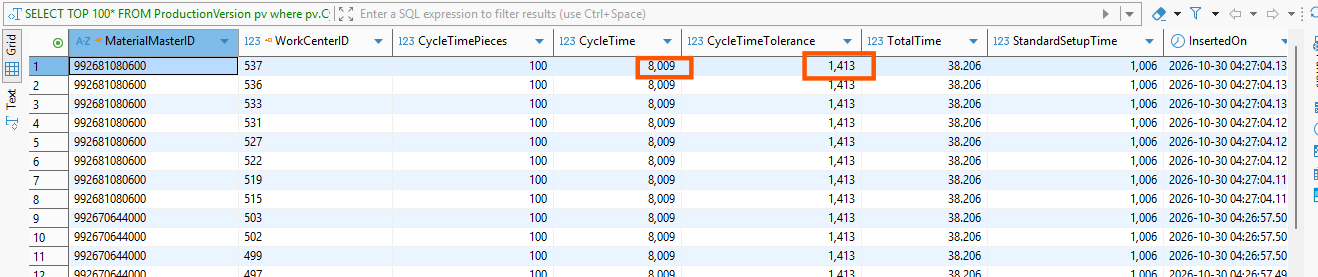
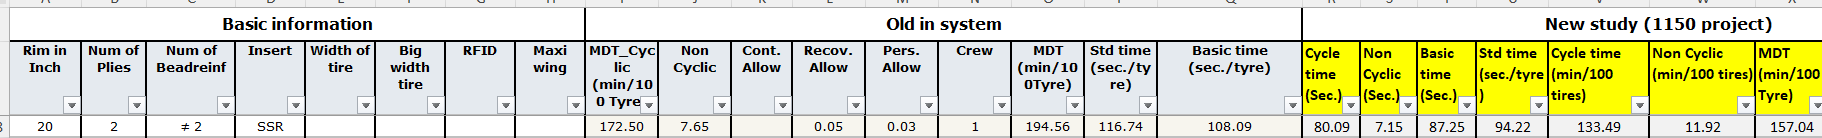
Take 9926809681 as example, "Cycle time"+"CycleTimeTolerance"=8009+1413=9422 seconds for 100 pcs tires

In [33]:
# ============================================================
# Step 20.4 - Recalculate IEStandardTotalTimePerTire
# Purpose:
# Update IE Standard Total Time in BOTH:
# 1. df_capacity_merged      -> master dataset
# 2. df_model_actualtime    -> current analysis dataset
#
# Formula:
# (CycleTimeTolerancePer100Tire
#  + IEStandardCycleTimePer100Tire) / 100
# ============================================================

# Update master dataset
df_capacity_merged["IEStandardTotalTimePerTire"] = (
    df_capacity_merged["CycleTimeTolerancePer100Tire"]
    + df_capacity_merged["IEStandardCycleTimePer100Tire"]
) / 100


# Update current analysis dataset
df_model_actualtime["IEStandardTotalTimePerTire"] = (
    df_model_actualtime["CycleTimeTolerancePer100Tire"]
    + df_model_actualtime["IEStandardCycleTimePer100Tire"]
) / 100


print("✅ IEStandardTotalTimePerTire updated in both DataFrames.")

# Quick check
display(
    df_model_actualtime[
        [
            "CycleTimeTolerancePer100Tire",
            "IEStandardCycleTimePer100Tire",
            "IEStandardTotalTimePerTire",
            "ActualTimePerTire"
        ]
    ].head(10)
)

✅ IEStandardTotalTimePerTire updated in both DataFrames.


,CycleTimeTolerancePer100Tire,IEStandardCycleTimePer100Tire,IEStandardTotalTimePerTire,ActualTimePerTire
0,1096.0,4675.0,57.71,66.366667
1,1096.0,4675.0,57.71,66.366667
2,1091.0,5233.0,63.24,73.461538
3,1091.0,5233.0,63.24,73.461538
5,1120.0,7184.0,83.04,85.416667
6,1096.0,4675.0,57.71,75.076923
7,1096.0,4675.0,57.71,75.076923
8,1035.0,4533.0,55.68,80.925234
9,1035.0,4533.0,55.68,80.925234
10,1035.0,4533.0,55.68,80.925234


In [34]:
# ============================================================
# Step 21 - Recalculate Numeric Feature Correlation
# Purpose:
# 1. Use cleaned ActualTimePerTire dataset
# 2. Use the corrected IEStandardTotalTimePerTire
# 3. Calculate correlation between all numeric X and Y
# 4. Rank features by absolute correlation strength
# ============================================================

Y_COLUMN = "ActualTimePerTire"

# Select numeric columns
numeric_cols_model = df_model_actualtime.select_dtypes(
    include=["number"]
).columns

# Calculate correlation with Y
correlation_with_y = (
    df_model_actualtime[numeric_cols_model]
    .corr()[Y_COLUMN]
    .drop(Y_COLUMN)
    .sort_values(key=abs, ascending=False)
    .reset_index()
)

correlation_with_y.columns = [
    "Feature",
    "Correlation_with_ActualTimePerTire"
]

display(correlation_with_y)

,Feature,Correlation_with_ActualTimePerTire
0,IEStandardTotalTimePerTire,0.639178
1,IEStandardCycleTimePer100Tire,0.635451
2,CycleTimeTolerancePer100Tire,0.387587
3,QuantityDone,-0.342615
4,PlannedQuantity,-0.316919
5,1_belt_-_cf_epdm,-0.204478
6,RecipeID,0.085584
7,WorkCenterID,0.069713
8,postcureinflation_active,0.067650
9,1_wound_cap_ply_-_ptc_max,-0.065956


The effectiveness of IE standard time is verified with 0.639 correlation, now we change Y to be the GAP between actual time per tire with standard time per tire. 

In [35]:
# ============================================================
# Step 22 - Create New Target Variable Y: Actual vs IE Gap
# Purpose:
# 1. Keep df_capacity_merged unchanged
# 2. Create a new dataframe for GAP analysis
# 3. Define new Y as:
#    ActualTimePerTire - IEStandardTotalTimePerTire
# ============================================================

# Start from the master dataset
df_model_gap = df_capacity_merged.copy()

# Create new Y
df_model_gap["ActualVsIEGap"] = (
    df_model_gap["ActualTimePerTire"]
    - df_model_gap["IEStandardTotalTimePerTire"]
)

Y_COLUMN = "ActualVsIEGap"

print("New Y:", Y_COLUMN)
print("Dataset shape:", df_model_gap.shape)

print("\n=== GAP Statistics ===")
display(df_model_gap[Y_COLUMN].describe())

print("\nMissing values:", df_model_gap[Y_COLUMN].isna().sum())

New Y: ActualVsIEGap
Dataset shape: (61343, 159)

=== GAP Statistics ===


count    61311.000000
mean        69.675511
std       1032.827738
min        -11.367778
25%         12.738419
50%         18.646818
75%         27.575011
max      62252.810000
Name: ActualVsIEGap, dtype: float64


Missing values: 32


In [36]:
# ============================================================
# Step 23 - Clean df_model_gap Directly
# Purpose:
# 1. Remove missing ActualVsIEGap values
# 2. Remove ActualVsIEGap outliers using IQR
# 3. Update df_model_gap directly
# ============================================================

Y_COLUMN = "ActualVsIEGap"

# Original row count
original_rows = len(df_model_gap)

# 1. Remove missing Y
missing_count = df_model_gap[Y_COLUMN].isna().sum()

df_model_gap = (
    df_model_gap
    .dropna(subset=[Y_COLUMN])
    .copy()
)

# 2. Calculate IQR
Q1 = df_model_gap[Y_COLUMN].quantile(0.25)
Q3 = df_model_gap[Y_COLUMN].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Remove outliers directly from df_model_gap
df_model_gap = df_model_gap[
    df_model_gap[Y_COLUMN].between(
        lower_bound,
        upper_bound
    )
].copy()

# 4. Reset index
df_model_gap.reset_index(drop=True, inplace=True)

# 5. Check result
print("=== ActualVsIEGap Cleaning Result ===")

print(f"Lower bound       : {lower_bound:.2f}")
print(f"Upper bound       : {upper_bound:.2f}")

print("\nOriginal rows     :", original_rows)
print("Missing removed   :", missing_count)
print("Final rows        :", len(df_model_gap))
print("Total removed     :", original_rows - len(df_model_gap))

removed_pct = (
    (original_rows - len(df_model_gap))
    / original_rows
    * 100
)

print(f"Removed percentage: {removed_pct:.2f}%")

print("\n=== Clean GAP Statistics ===")
display(df_model_gap[Y_COLUMN].describe())

=== ActualVsIEGap Cleaning Result ===
Lower bound       : -9.52
Upper bound       : 49.83

Original rows     : 61343
Missing removed   : 32
Final rows        : 56474
Total removed     : 4869
Removed percentage: 7.94%

=== Clean GAP Statistics ===


count    56474.000000
mean        19.186171
std         10.023639
min         -9.444031
25%         12.276000
50%         17.619375
75%         24.757727
max         49.812222
Name: ActualVsIEGap, dtype: float64

In [38]:
# ============================================================
# Step 23 - Numeric Feature Correlation with ActualVsIEGap
# Purpose:
# 1. Use the cleaned df_model_gap
# 2. Analyze all numeric features, including joined Redshift data
# 3. Rank correlations with the new Y: ActualVsIEGap
# ============================================================

Y_COLUMN = "ActualVsIEGap"

# Select all numeric columns from the joined and cleaned dataset
numeric_cols_gap = df_model_gap.select_dtypes(
    include=["number"]
).columns

# Calculate correlation with the new Y
correlation_with_gap = (
    df_model_gap[numeric_cols_gap]
    .corr()[Y_COLUMN]
    .drop(Y_COLUMN)
    .dropna()
    .sort_values(key=abs, ascending=False)
    .reset_index()
)

correlation_with_gap.columns = [
    "Feature",
    "Correlation_with_ActualVsIEGap"
]

print("Dataset used       : df_model_gap")
print("Rows analyzed      :", len(df_model_gap))
print("Numeric X analyzed :", len(correlation_with_gap))

display(correlation_with_gap)

Dataset used       : df_model_gap
Rows analyzed      : 56474
Numeric X analyzed : 17


,Feature,Correlation_with_ActualVsIEGap
0,ActualTimePerTire,0.758251
1,QuantityDone,-0.399584
2,PlannedQuantity,-0.377833
3,ActualProcessingTime,-0.175169
4,OperatorOverlapSeconds,-0.150194
5,1_wound_cap_ply_-_ptc_max,-0.140299
6,IEStandardCycleTimePer100Tire,0.135247
7,IEStandardTotalTimePerTire,0.129198
8,WorkCenterID,0.121488
9,1_belt_-_cf_epdm,-0.060477


In [43]:
# ============================================================
# Step 24 - Feature Classification
# Purpose:
# 1. Define target Y
# 2. Remove leakage variables from X
# 3. Only ignore TRUE identifiers / join keys
# 4. Treat Shift / WorkCenter / Recipe / Operator as categorical
# 5. Rescue Redshift tire structure/spec features
# 6. Do NOT delete any columns from df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Target Y
# ------------------------------------------------------------

target_col = "ActualVsIEGap"


# ------------------------------------------------------------
# 2. Leakage columns
# These fields directly contain or contribute to Y
# ------------------------------------------------------------

leakage_cols = [
    "ActualTimePerTire",
    "ActualProcessingTime",
    "IEStandardTotalTimePerTire"
]

leakage_cols = [
    col for col in leakage_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 3. TRUE identifiers / join keys
# Only fields primarily used for record identification,
# traceability or table joining
# ------------------------------------------------------------

true_identifier_cols = [
    "OrderID",
    "OrderIDLinked",
    "OrderIDCoupled",
    "PLCOrderNumber",
    "MaterialMasterID",
    "MaterialMasterIDCoupled",
    "GT_MappingKey",
    "articleid",
    "base_articleid",
    "greentire_gutsid",
    "greentire_localworkcode",
    "carcass_localworkcode",
    "OperatorEmployeeNumber",
    "OperatorWorkcenterRoleCatalogID"
]

identifier_cols = [
    col for col in true_identifier_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 4. Known categorical business features
# These may look numeric but represent categories
# ------------------------------------------------------------

known_categorical_cols = [
    "ShiftNumber",
    "WorkCenterID",
    "RecipeID",
    "OperatorUserID"
]

known_categorical_cols = [
    col for col in known_categorical_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 5. Detect all numeric columns
# ------------------------------------------------------------

all_numeric_cols = (
    df_model_gap
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)


# ------------------------------------------------------------
# 6. True numeric features
#
# Important:
# Tire structure fields such as width / weight / thickness /
# angle / diameter etc. are now kept if their dtype is numeric.
# ------------------------------------------------------------

numeric_feature_cols = [
    col for col in all_numeric_cols
    if col != target_col
    and col not in leakage_cols
    and col not in identifier_cols
    and col not in known_categorical_cols
]


# ------------------------------------------------------------
# 7. Detect non-numeric columns
# ------------------------------------------------------------

all_non_numeric_cols = (
    df_model_gap
    .select_dtypes(exclude=["number"])
    .columns
    .tolist()
)


# ------------------------------------------------------------
# 8. Categorical features
#
# Includes:
# - Shift
# - WorkCenter
# - Recipe
# - Operator
# - Tire structure/spec categorical fields
# - Redshift compound / construction / geometry etc.
# ------------------------------------------------------------

categorical_feature_cols = (
    known_categorical_cols
    +
    [
        col for col in all_non_numeric_cols
        if col not in identifier_cols
        and col not in leakage_cols
        and col != target_col
    ]
)

# Remove duplicates while preserving order
categorical_feature_cols = list(
    dict.fromkeys(categorical_feature_cols)
)


# ------------------------------------------------------------
# 9. Final safety check
# ------------------------------------------------------------

classified_cols = set(
    [target_col]
    + leakage_cols
    + identifier_cols
    + numeric_feature_cols
    + categorical_feature_cols
)

unclassified_cols = [
    col for col in df_model_gap.columns
    if col not in classified_cols
]


# ------------------------------------------------------------
# 10. Print classification summary
# ------------------------------------------------------------

print("=== Revised Feature Classification Summary ===")

print("\nTarget:")
print(target_col)


print("\nLeakage columns:", len(leakage_cols))
print(leakage_cols)


print("\nTrue Numeric Features:", len(numeric_feature_cols))
for col in numeric_feature_cols:
    print("  ", col)


print("\nCategorical Features:", len(categorical_feature_cols))
for col in categorical_feature_cols:
    print("  ", col)


print("\nTrue Identifier / Ignore Columns:", len(identifier_cols))
for col in identifier_cols:
    print("  ", col)


print("\nUnclassified Columns:", len(unclassified_cols))
print(unclassified_cols)

=== Revised Feature Classification Summary ===

Target:
ActualVsIEGap

Leakage columns: 3
['ActualTimePerTire', 'ActualProcessingTime', 'IEStandardTotalTimePerTire']

True Numeric Features: 14
   PlannedQuantity
   QuantityDone
   UserIDInsertedBy
   CycleTimePieces
   IEStandardCycleTimePer100Tire
   CycleTimeTolerancePer100Tire
   StandardSetupTimePer100Tire
   OperatorOverlapSeconds
   OperatorCoverageRatio
   from_tran
   postcureinflation_active
   1_belt_-_cf_epdm
   1_wound_cap_ply_-_ptc_min
   1_wound_cap_ply_-_ptc_max

Categorical Features: 127
   ShiftNumber
   WorkCenterID
   RecipeID
   OperatorUserID
   Comment
   ShiftDate
   ActualStartTime
   ActualEndTime
   PlannedStartTime
   PlannedEndTime
   ProdVersion
   ProdVariant
   DestinationInfo
   ETOFlag
   StatusUpdatedOn
   IsParent
   CreatedByCGMS
   InsertedOn
   UpdatedOn
   ExtTerminated
   WorkCenterNameCoupled
   PhaseInOut
   IsGAPOrder
   OrderStatus
   WorkCenterName
   OperatorStartDate
   OperatorEndDate
   

In [44]:
# ============================================================
# Step 25 - Detect Numeric-like Structure Features
# Purpose:
# 1. Check categorical tire structure/spec fields
# 2. Identify columns that are actually numeric values
# 3. Do NOT modify df_model_gap yet
# ============================================================

import pandas as pd

# Keywords that usually represent numerical physical properties
numeric_spec_keywords = [
    "width",
    "diameter",
    "thickness",
    "weight",
    "angle",
    "circumference",
    "gradient"
]

# Find candidate columns
numeric_spec_candidates = [
    col for col in categorical_feature_cols
    if any(
        keyword in col.lower()
        for keyword in numeric_spec_keywords
    )
]

conversion_check = []

for col in numeric_spec_candidates:

    original = df_model_gap[col]

    # Try numeric conversion
    converted = pd.to_numeric(
        original,
        errors="coerce"
    )

    non_null_original = original.notna().sum()
    non_null_numeric = converted.notna().sum()

    if non_null_original > 0:
        conversion_rate = (
            non_null_numeric
            / non_null_original
            * 100
        )
    else:
        conversion_rate = 0

    conversion_check.append({
        "Feature": col,
        "Current_Dtype": str(original.dtype),
        "Non_Null": non_null_original,
        "Numeric_Values": non_null_numeric,
        "Conversion_Rate_%": round(conversion_rate, 2),
        "Unique_Values": original.nunique()
    })

numeric_conversion_review = (
    pd.DataFrame(conversion_check)
    .sort_values(
        "Conversion_Rate_%",
        ascending=False
    )
)

display(numeric_conversion_review)

,Feature,Current_Dtype,Non_Null,Numeric_Values,Conversion_Rate_%,Unique_Values
0,rim_diameter,object,56474,56474,100.0,9
1,1_stage_drum_width,object,56396,56396,100.0,89
2,2_stage_drum_diameter,object,56396,56396,100.0,185
3,1_liner_-_width,object,56396,56396,100.0,24
4,1_liner_-_thickness,object,56396,56396,100.0,3
5,1_apex_-_width,object,56396,56396,100.0,12
6,1_apex_-_thickness,object,56396,56396,100.0,14
7,bead_-_bead_inner_diameter,object,56396,56396,100.0,18
8,bead_-_bead_circumference,object,56396,56396,100.0,18
9,1_ply_assembly_-_1_strip_rubber_-_width,object,695,695,100.0,2


In [45]:
# ============================================================
# Step 26 - Convert Numeric-like Specification Features
# Purpose:
# 1. Convert structure/spec fields with >=95% numeric values
# 2. Move them from categorical to numeric features
# 3. Keep low-conversion fields as categorical
# 4. Do not remove rows or columns
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Select columns with >= 95% numeric conversion rate
# ------------------------------------------------------------

spec_cols_to_numeric = (
    numeric_conversion_review.loc[
        numeric_conversion_review["Conversion_Rate_%"] >= 95,
        "Feature"
    ]
    .tolist()
)

print("Spec columns to convert:", len(spec_cols_to_numeric))


# ------------------------------------------------------------
# 2. Convert selected spec columns to numeric
# ------------------------------------------------------------

for col in spec_cols_to_numeric:
    df_model_gap[col] = pd.to_numeric(
        df_model_gap[col],
        errors="coerce"
    )


# ------------------------------------------------------------
# 3. Update numeric feature list
# ------------------------------------------------------------

numeric_feature_cols = list(
    dict.fromkeys(
        numeric_feature_cols
        + spec_cols_to_numeric
    )
)


# ------------------------------------------------------------
# 4. Remove converted columns from categorical feature list
# ------------------------------------------------------------

categorical_feature_cols = [
    col for col in categorical_feature_cols
    if col not in spec_cols_to_numeric
]


# ------------------------------------------------------------
# 5. UserIDInsertedBy should not be a continuous numeric feature
# ------------------------------------------------------------

if "UserIDInsertedBy" in numeric_feature_cols:
    numeric_feature_cols.remove("UserIDInsertedBy")

if "UserIDInsertedBy" not in identifier_cols:
    identifier_cols.append("UserIDInsertedBy")


# ------------------------------------------------------------
# 6. Safety check
# ------------------------------------------------------------

print("\n=== Updated Feature Classification ===")

print("Numeric Features     :", len(numeric_feature_cols))
print("Categorical Features :", len(categorical_feature_cols))
print("Identifier / Ignore  :", len(identifier_cols))


print("\nConverted Spec Features:")
for col in spec_cols_to_numeric:
    print(
        f"{col:<55} -> {df_model_gap[col].dtype}"
    )


print("\nKept as Categorical:")

spec_cols_kept_categorical = [
    col for col in numeric_spec_candidates
    if col not in spec_cols_to_numeric
]

for col in spec_cols_kept_categorical:
    print(col)

Spec columns to convert: 28

=== Updated Feature Classification ===
Numeric Features     : 41
Categorical Features : 99
Identifier / Ignore  : 15

Converted Spec Features:
rim_diameter                                            -> float64
1_stage_drum_width                                      -> float64
2_stage_drum_diameter                                   -> float64
1_liner_-_width                                         -> float64
1_liner_-_thickness                                     -> float64
1_apex_-_width                                          -> float64
1_apex_-_thickness                                      -> float64
bead_-_bead_inner_diameter                              -> float64
bead_-_bead_circumference                               -> float64
1_ply_assembly_-_1_strip_rubber_-_width                 -> float64
1_ply_assembly_-_1_strip_rubber_-_thickness             -> float64
1_carcass_ply_-_width                                   -> float64
2_carcass_ply_-_width   

In [48]:
# ============================================================
# Step 27 - Feature Quality Screening
# Purpose:
# 1. Review all candidate X features
# 2. Calculate missing rate
# 3. Calculate unique value count
# 4. Check numeric and categorical feature quality
# 5. Print full result as plain text for review
# 6. Do NOT remove any features yet
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Combine all candidate X features
# ------------------------------------------------------------

candidate_features = (
    numeric_feature_cols
    + categorical_feature_cols
)


# ------------------------------------------------------------
# 2. Calculate feature quality information
# ------------------------------------------------------------

feature_quality = []

for col in candidate_features:

    total_rows = len(df_model_gap)

    non_null_count = df_model_gap[col].notna().sum()
    missing_count = df_model_gap[col].isna().sum()

    missing_pct = (
        missing_count / total_rows * 100
    )

    unique_count = df_model_gap[col].nunique(
        dropna=True
    )

    # Determine feature type
    if col in numeric_feature_cols:
        feature_type = "Numeric"
    else:
        feature_type = "Categorical"

    feature_quality.append({
        "Feature": col,
        "Type": feature_type,
        "Non_Null_Count": non_null_count,
        "Missing_%": round(missing_pct, 2),
        "Unique_Count": unique_count
    })


# ------------------------------------------------------------
# 3. Create Feature Quality dataframe
# ------------------------------------------------------------

feature_quality_df = pd.DataFrame(
    feature_quality
)


# ------------------------------------------------------------
# 4. Sort by missing rate
# ------------------------------------------------------------

feature_quality_df = (
    feature_quality_df
    .sort_values(
        by=["Missing_%", "Unique_Count"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. Display summary
# ------------------------------------------------------------

print(
    "Total candidate X features:",
    len(candidate_features)
)

display(feature_quality_df)


# ------------------------------------------------------------
# 6. Print COMPLETE result as plain text
# Purpose:
# Easy to copy and paste for detailed review
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("FULL FEATURE QUALITY RESULT")
print("=" * 100)

print(
    feature_quality_df.to_string(
        index=False
    )
)

Total candidate X features: 140


,Feature,Type,Non_Null_Count,Missing_%,Unique_Count
0,CreatedByCGMS,Categorical,0,100.00,0
1,stamping_code,Categorical,0,100.00,0
2,2_belt_ply_assembly_-_1_strip_rubber_-_thickness,Numeric,17,99.97,1
3,2_belt_ply_assembly_-_1_strip_rubber_-_width,Numeric,17,99.97,1
4,2_belt_ply_assembly_-_1_strip_rubber_-_bom_com...,Categorical,17,99.97,1
...,...,...,...,...,...
135,InsertedOn,Categorical,56474,0.00,21667
136,ActualStartTime,Categorical,56474,0.00,21701
137,ActualEndTime,Categorical,56474,0.00,21701
138,StatusUpdatedOn,Categorical,56474,0.00,21701




FULL FEATURE QUALITY RESULT
                                                     Feature        Type  Non_Null_Count  Missing_%  Unique_Count
                                               CreatedByCGMS Categorical               0     100.00             0
                                               stamping_code Categorical               0     100.00             0
            2_belt_ply_assembly_-_1_strip_rubber_-_thickness     Numeric              17      99.97             1
                2_belt_ply_assembly_-_1_strip_rubber_-_width     Numeric              17      99.97             1
2_belt_ply_assembly_-_1_strip_rubber_-_bom_component_setting Categorical              17      99.97             1
                 1_ply_assembly_-_1_strip_rubber_-_thickness     Numeric             695      98.77             1
                     1_ply_assembly_-_1_strip_rubber_-_width     Numeric             695      98.77             2
                  1_ply_assembly_-_1_strip_rubber_-_compou

In [50]:
# ============================================================
# Step 28 - Feature Engineering & Initial Cleanup
# Purpose:
# 1. Remove confirmed unusable / constant / system fields
# 2. Remove raw timestamp fields with leakage or low business value
# 3. Extract useful time features
# 4. Create structure-presence features from optional structures
# 5. Update df_model_gap directly
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Create useful time features BEFORE dropping raw timestamps
# ------------------------------------------------------------

# Convert to datetime safely
df_model_gap["ActualStartTime"] = pd.to_datetime(
    df_model_gap["ActualStartTime"],
    errors="coerce"
)

df_model_gap["PlannedStartTime"] = pd.to_datetime(
    df_model_gap["PlannedStartTime"],
    errors="coerce"
)

# Actual production timing features
df_model_gap["ActualStartHour"] = (
    df_model_gap["ActualStartTime"].dt.hour
)

df_model_gap["ActualStartDayOfWeek"] = (
    df_model_gap["ActualStartTime"].dt.dayofweek
)

df_model_gap["ActualStartMonth"] = (
    df_model_gap["ActualStartTime"].dt.month
)

# Planned production timing features
df_model_gap["PlannedStartHour"] = (
    df_model_gap["PlannedStartTime"].dt.hour
)

df_model_gap["PlannedStartDayOfWeek"] = (
    df_model_gap["PlannedStartTime"].dt.dayofweek
)

df_model_gap["PlannedStartMonth"] = (
    df_model_gap["PlannedStartTime"].dt.month
)


# ------------------------------------------------------------
# 2. Create optional tire-structure presence features
# Missing means that the structure is not present
# ------------------------------------------------------------

# 1st Ply Assembly - Strip Rubber
df_model_gap["Has_1st_Ply_Strip_Rubber"] = (
    df_model_gap[
        "1_ply_assembly_-_1_strip_rubber_-_compound"
    ]
    .notna()
    .astype(int)
)


# 2nd Belt - Strip Rubber
df_model_gap["Has_2nd_Belt_Strip_Rubber"] = (
    df_model_gap[
        "2_belt_ply_assembly_-_1_strip_rubber_-_bom_component_setting"
    ]
    .notna()
    .astype(int)
)


# 2nd Carcass Ply
df_model_gap["Has_2nd_Carcass_Ply"] = (
    df_model_gap[
        "2_carcass_ply_-_cf_code"
    ]
    .notna()
    .astype(int)
)


# Bead Reinforcement
df_model_gap["Has_Bead_Reinforcement"] = (
    df_model_gap[
        "1_bead_reinforcement_-_cf_code"
    ]
    .notna()
    .astype(int)
)


# ------------------------------------------------------------
# 3. Fields confirmed for removal
# ------------------------------------------------------------

cols_to_drop = [

    # Completely empty
    "CreatedByCGMS",
    "stamping_code",

    # Random Redshift spec - confirmed unreliable
    "enrichment_type",

    # Constant / no variation
    "CycleTimePieces",
    "StandardSetupTimePer100Tire",
    "from_tran",
    "ssr_flag",
    "OperatorIsTeamLeader",
    "IsParent",
    "drum_profile-no",
    "1_belt_-_cf_compound_top",
    "1_belt_ply_assembly_-_1_strip_rubber_-_compound",
    "1_bead_reinforcement_-_cf_code",
    "ProdVariant",
    "ETOFlag",
    "IsGAPOrder",
    "OrderStatus",
    "plant_dot_code",
    "base_plant_dot_code",
    "product_line_id",
    "tire_group_description",

    # Raw production timestamps
    "ActualStartTime",
    "ActualEndTime",
    "PlannedStartTime",
    "PlannedEndTime",

    # Operator raw timestamps
    # Keep OperatorOverlapSeconds + OperatorCoverageRatio instead
    "OperatorStartDate",
    "OperatorEndDate",
    "OperatorOverlapStart",
    "OperatorOverlapEnd",

    # System / master-data timestamps
    "InsertedOn",
    "UpdatedOn",
    "StatusUpdatedOn",
    "src_created_timestamp",
    "src_last_modified_timestamp",
    "base_src_created_timestamp",
    "base_src_last_modified_timestamp",
    "created_utc_timestamp",
    "last_modified_utc_timestamp",

    # Extremely sparse original fields replaced by Has_xxx
    "1_ply_assembly_-_1_strip_rubber_-_width",
    "1_ply_assembly_-_1_strip_rubber_-_thickness",

    "2_belt_ply_assembly_-_1_strip_rubber_-_thickness",
    "2_belt_ply_assembly_-_1_strip_rubber_-_width",
    "2_belt_ply_assembly_-_1_strip_rubber_-_bom_component_setting"
]


# Only drop fields that actually exist
cols_to_drop = [
    col for col in cols_to_drop
    if col in df_model_gap.columns
]

df_model_gap.drop(
    columns=cols_to_drop,
    inplace=True
)


# ------------------------------------------------------------
# 4. Check result
# ------------------------------------------------------------

print("=== Step 28 Result ===")

print("Rows remaining    :", len(df_model_gap))
print("Columns remaining :", len(df_model_gap.columns))
print("Columns removed   :", len(cols_to_drop))


print("\n=== New Time Features ===")

time_features = [
    "ActualStartHour",
    "ActualStartDayOfWeek",
    "ActualStartMonth",
    "PlannedStartHour",
    "PlannedStartDayOfWeek",
    "PlannedStartMonth"
]

display(
    df_model_gap[time_features]
    .describe()
    .T
)


print("\n=== New Structure Presence Features ===")

structure_presence_features = [
    "Has_1st_Ply_Strip_Rubber",
    "Has_2nd_Belt_Strip_Rubber",
    "Has_2nd_Carcass_Ply",
    "Has_Bead_Reinforcement"
]

for col in structure_presence_features:
    print(f"\n{col}")
    print(df_model_gap[col].value_counts(dropna=False))

=== Step 28 Result ===
Rows remaining    : 56474
Columns remaining : 126
Columns removed   : 43

=== New Time Features ===


,count,mean,std,min,25%,50%,75%,max
ActualStartHour,56474.0,12.051581,6.906478,0.0,6.0,12.0,18.0,23.0
ActualStartDayOfWeek,56474.0,3.027234,2.031092,0.0,1.0,3.0,5.0,6.0
ActualStartMonth,56474.0,9.500903,0.690611,8.0,9.0,10.0,10.0,11.0
PlannedStartHour,56474.0,11.622694,6.906357,0.0,6.0,12.0,18.0,23.0
PlannedStartDayOfWeek,56474.0,3.031076,2.029489,0.0,1.0,3.0,5.0,6.0
PlannedStartMonth,56474.0,9.501133,0.690380,8.0,9.0,10.0,10.0,11.0



=== New Structure Presence Features ===

Has_1st_Ply_Strip_Rubber
Has_1st_Ply_Strip_Rubber
0    55779
1      695
Name: count, dtype: int64

Has_2nd_Belt_Strip_Rubber
Has_2nd_Belt_Strip_Rubber
0    56457
1       17
Name: count, dtype: int64

Has_2nd_Carcass_Ply
Has_2nd_Carcass_Ply
0    50266
1     6208
Name: count, dtype: int64

Has_Bead_Reinforcement
Has_Bead_Reinforcement
0    50855
1     5619
Name: count, dtype: int64


In [51]:
# ============================================================
# Step 29 - Build Final Feature List
# Purpose:
# 1. Rebuild feature lists after Step 28 cleanup
# 2. Separate Numeric / Categorical / Identifier / Leakage
# 3. Include newly engineered time and structure features
# 4. Do NOT modify df_model_gap
# ============================================================

# ------------------------------------------------------------
# 1. Target
# ------------------------------------------------------------

target_col = "ActualVsIEGap"


# ------------------------------------------------------------
# 2. Leakage features
# Directly involved in the target calculation
# ------------------------------------------------------------

leakage_cols = [
    "ActualTimePerTire",
    "ActualProcessingTime",
    "IEStandardTotalTimePerTire"
]

leakage_cols = [
    col for col in leakage_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 3. True identifiers / join keys
# Keep in dataset for traceability, but do NOT use as model X
# ------------------------------------------------------------

identifier_cols = [
    "OrderID",
    "OrderIDLinked",
    "OrderIDCoupled",
    "PLCOrderNumber",
    "MaterialMasterID",
    "MaterialMasterIDCoupled",
    "GT_MappingKey",
    "articleid",
    "base_articleid",
    "greentire_gutsid",
    "greentire_localworkcode",
    "carcass_localworkcode",
    "OperatorEmployeeNumber",
    "OperatorWorkcenterRoleCatalogID",
    "UserIDInsertedBy"
]

identifier_cols = [
    col for col in identifier_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 4. Business categorical features
# These may be stored as numbers but represent categories
# ------------------------------------------------------------

business_categorical_cols = [
    "ShiftNumber",
    "WorkCenterID",
    "RecipeID",
    "OperatorUserID",

    # Engineered time features
    "ActualStartHour",
    "ActualStartDayOfWeek",
    "ActualStartMonth",
    "PlannedStartHour",
    "PlannedStartDayOfWeek",
    "PlannedStartMonth"
]

business_categorical_cols = [
    col for col in business_categorical_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 5. Automatically identify current numeric columns
# ------------------------------------------------------------

all_numeric_cols = (
    df_model_gap
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)


# ------------------------------------------------------------
# 6. Final Numeric Features
# ------------------------------------------------------------

numeric_feature_cols = [
    col for col in all_numeric_cols
    if col != target_col
    and col not in leakage_cols
    and col not in identifier_cols
    and col not in business_categorical_cols
]


# ------------------------------------------------------------
# 7. Automatically identify current non-numeric columns
# ------------------------------------------------------------

all_non_numeric_cols = (
    df_model_gap
    .select_dtypes(exclude=["number"])
    .columns
    .tolist()
)


# ------------------------------------------------------------
# 8. Final Categorical Features
# ------------------------------------------------------------

categorical_feature_cols = (
    business_categorical_cols
    + [
        col for col in all_non_numeric_cols
        if col != target_col
        and col not in leakage_cols
        and col not in identifier_cols
    ]
)

# Remove duplicates
categorical_feature_cols = list(
    dict.fromkeys(categorical_feature_cols)
)


# ------------------------------------------------------------
# 9. Final model feature list
# ------------------------------------------------------------

final_feature_cols = (
    numeric_feature_cols
    + categorical_feature_cols
)


# ------------------------------------------------------------
# 10. Safety checks
# ------------------------------------------------------------

classified_cols = set(
    [target_col]
    + leakage_cols
    + identifier_cols
    + final_feature_cols
)

unclassified_cols = [
    col for col in df_model_gap.columns
    if col not in classified_cols
]

duplicate_features = (
    pd.Series(final_feature_cols)
    .value_counts()
)

duplicate_features = duplicate_features[
    duplicate_features > 1
]


# ------------------------------------------------------------
# 11. Summary
# ------------------------------------------------------------

print("=== Step 29 - Final Feature List ===")

print("\nDataset:")
print("Rows    :", len(df_model_gap))
print("Columns :", len(df_model_gap.columns))

print("\nTarget:")
print(target_col)

print("\nNumeric X       :", len(numeric_feature_cols))
print("Categorical X   :", len(categorical_feature_cols))
print("Total Model X   :", len(final_feature_cols))

print("\nLeakage / Excluded:", len(leakage_cols))
print(leakage_cols)

print("\nIdentifier / Traceability:", len(identifier_cols))
print(identifier_cols)

print("\nUnclassified Columns:", len(unclassified_cols))
print(unclassified_cols)

print("\nDuplicate Features:", len(duplicate_features))
print(duplicate_features.index.tolist())


# ------------------------------------------------------------
# 12. Display final Numeric X
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL NUMERIC FEATURES")
print("=" * 80)

for i, col in enumerate(numeric_feature_cols, 1):
    print(f"{i:2}. {col}")


# ------------------------------------------------------------
# 13. Display final Categorical X
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL CATEGORICAL FEATURES")
print("=" * 80)

for i, col in enumerate(categorical_feature_cols, 1):
    print(f"{i:3}. {col}")

=== Step 29 - Final Feature List ===

Dataset:
Rows    : 56474
Columns : 126

Target:
ActualVsIEGap

Numeric X       : 38
Categorical X   : 69
Total Model X   : 107

Leakage / Excluded: 3
['ActualTimePerTire', 'ActualProcessingTime', 'IEStandardTotalTimePerTire']

Identifier / Traceability: 15
['OrderID', 'OrderIDLinked', 'OrderIDCoupled', 'PLCOrderNumber', 'MaterialMasterID', 'MaterialMasterIDCoupled', 'GT_MappingKey', 'articleid', 'base_articleid', 'greentire_gutsid', 'greentire_localworkcode', 'carcass_localworkcode', 'OperatorEmployeeNumber', 'OperatorWorkcenterRoleCatalogID', 'UserIDInsertedBy']

Unclassified Columns: 0
[]

Duplicate Features: 0
[]

FINAL NUMERIC FEATURES
 1. PlannedQuantity
 2. QuantityDone
 3. IEStandardCycleTimePer100Tire
 4. CycleTimeTolerancePer100Tire
 5. OperatorOverlapSeconds
 6. OperatorCoverageRatio
 7. rim_diameter
 8. postcureinflation_active
 9. 1_stage_drum_width
10. 2_stage_drum_diameter
11. 1_liner_-_width
12. 1_liner_-_thickness
13. 1_apex_-_width

In [52]:
# ============================================================
# Step 30 - Numeric Feature Analysis with ActualVsIEGap
# Purpose:
# 1. Analyze the final 38 numeric features
# 2. Calculate Pearson correlation with ActualVsIEGap
# 3. Rank features by absolute correlation strength
# 4. Keep correlation direction for business interpretation
# 5. Do NOT modify df_model_gap
# ============================================================

import pandas as pd

Y_COLUMN = "ActualVsIEGap"


# ------------------------------------------------------------
# 1. Calculate correlation for final numeric features only
# ------------------------------------------------------------

numeric_correlation = (
    df_model_gap[
        numeric_feature_cols + [Y_COLUMN]
    ]
    .corr()[Y_COLUMN]
    .drop(Y_COLUMN)
    .reset_index()
)

numeric_correlation.columns = [
    "Feature",
    "Correlation"
]


# ------------------------------------------------------------
# 2. Add absolute correlation for ranking
# ------------------------------------------------------------

numeric_correlation["Abs_Correlation"] = (
    numeric_correlation["Correlation"].abs()
)


# ------------------------------------------------------------
# 3. Add data coverage information
# ------------------------------------------------------------

numeric_correlation["Non_Null_Count"] = (
    numeric_correlation["Feature"]
    .map(
        df_model_gap[numeric_feature_cols]
        .notna()
        .sum()
    )
)

numeric_correlation["Missing_%"] = (
    100
    - numeric_correlation["Non_Null_Count"]
    / len(df_model_gap)
    * 100
).round(2)


# ------------------------------------------------------------
# 4. Sort by correlation strength
# ------------------------------------------------------------

numeric_correlation = (
    numeric_correlation
    .sort_values(
        "Abs_Correlation",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. Display result
# ------------------------------------------------------------

print("=== Step 30 - Numeric Feature Analysis ===")

print("Target                 :", Y_COLUMN)
print("Numeric features tested:", len(numeric_feature_cols))
print("Rows                   :", len(df_model_gap))

display(numeric_correlation)


# ------------------------------------------------------------
# 6. Print complete result for easy review
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FULL NUMERIC CORRELATION RESULT")
print("=" * 100)

print(
    numeric_correlation.to_string(
        index=False
    )
)

=== Step 30 - Numeric Feature Analysis ===
Target                 : ActualVsIEGap
Numeric features tested: 38
Rows                   : 56474


,Feature,Correlation,Abs_Correlation,Non_Null_Count,Missing_%
0,QuantityDone,-0.399584,0.399584,56474,0.00
1,PlannedQuantity,-0.377833,0.377833,56474,0.00
2,2_carcass_ply_-_thickness,-0.243675,0.243675,6208,89.01
3,1_tread_base_-_width,0.177111,0.177111,56396,0.14
4,OperatorOverlapSeconds,-0.150194,0.150194,54017,4.35
5,1_wound_cap_ply_-_ptc_max,-0.140299,0.140299,56355,0.21
6,IEStandardCycleTimePer100Tire,0.135247,0.135247,56474,0.00
7,Has_2nd_Carcass_Ply,0.105602,0.105602,56474,0.00
8,2_carcass_ply_-_width,-0.097303,0.097303,6208,89.01
9,1_bead_reinforcement_-_width,-0.088136,0.088136,5619,90.05



FULL NUMERIC CORRELATION RESULT
                                     Feature  Correlation  Abs_Correlation  Non_Null_Count  Missing_%
                                QuantityDone    -0.399584         0.399584           56474       0.00
                             PlannedQuantity    -0.377833         0.377833           56474       0.00
                   2_carcass_ply_-_thickness    -0.243675         0.243675            6208      89.01
                        1_tread_base_-_width     0.177111         0.177111           56396       0.14
                      OperatorOverlapSeconds    -0.150194         0.150194           54017       4.35
                   1_wound_cap_ply_-_ptc_max    -0.140299         0.140299           56355       0.21
               IEStandardCycleTimePer100Tire     0.135247         0.135247           56474       0.00
                         Has_2nd_Carcass_Ply     0.105602         0.105602           56474       0.00
                       2_carcass_ply_-_width    -

In [53]:
# ============================================================
# Step 31 - Categorical Feature Analysis with ActualVsIEGap
# Purpose:
# 1. Analyze final categorical features
# 2. Measure how much Y varies across categories
# 3. Calculate Eta Squared (η²) as effect size
# 4. Track category count and data coverage
# 5. Do NOT modify df_model_gap
# ============================================================

import pandas as pd
import numpy as np

Y_COLUMN = "ActualVsIEGap"

categorical_analysis = []


# ------------------------------------------------------------
# 1. Calculate Eta Squared for each categorical feature
# ------------------------------------------------------------

for col in categorical_feature_cols:

    temp = df_model_gap[[col, Y_COLUMN]].dropna()

    if len(temp) == 0:
        continue

    n_unique = temp[col].nunique()

    # Need at least 2 categories
    if n_unique <= 1:
        continue

    # Overall Y mean
    overall_mean = temp[Y_COLUMN].mean()

    # Total sum of squares
    ss_total = (
        (temp[Y_COLUMN] - overall_mean) ** 2
    ).sum()

    # Between-group sum of squares
    group_stats = (
        temp
        .groupby(col, observed=True)[Y_COLUMN]
        .agg(["count", "mean"])
    )

    ss_between = (
        group_stats["count"]
        * (group_stats["mean"] - overall_mean) ** 2
    ).sum()

    # Eta squared
    eta_squared = (
        ss_between / ss_total
        if ss_total > 0
        else np.nan
    )

    non_null_count = df_model_gap[col].notna().sum()

    missing_pct = (
        1 - non_null_count / len(df_model_gap)
    ) * 100

    categorical_analysis.append({
        "Feature": col,
        "Eta_Squared": eta_squared,
        "Unique_Categories": n_unique,
        "Non_Null_Count": non_null_count,
        "Missing_%": round(missing_pct, 2)
    })


# ------------------------------------------------------------
# 2. Create result dataframe
# ------------------------------------------------------------

categorical_analysis_df = pd.DataFrame(
    categorical_analysis
)


# ------------------------------------------------------------
# 3. Rank by Eta Squared
# ------------------------------------------------------------

categorical_analysis_df = (
    categorical_analysis_df
    .sort_values(
        "Eta_Squared",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Display result
# ------------------------------------------------------------

print("=== Step 31 - Categorical Feature Analysis ===")

print("Target                      :", Y_COLUMN)
print("Categorical features tested :", len(categorical_analysis_df))
print("Rows                        :", len(df_model_gap))

display(categorical_analysis_df)


# ------------------------------------------------------------
# 5. Print complete result for review
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FULL CATEGORICAL FEATURE ANALYSIS")
print("=" * 100)

print(
    categorical_analysis_df.to_string(
        index=False
    )
)

=== Step 31 - Categorical Feature Analysis ===
Target                      : ActualVsIEGap
Categorical features tested : 69
Rows                        : 56474


,Feature,Eta_Squared,Unique_Categories,Non_Null_Count,Missing_%
0,RecipeID,3.450428e-01,730,56474,0.00
1,greentire_code,3.216148e-01,637,56474,0.00
2,article_pk,3.216148e-01,637,56474,0.00
3,article7,3.213631e-01,629,56474,0.00
4,base_article7,3.213466e-01,628,56474,0.00
...,...,...,...,...,...
64,ActualStartMonth,2.713597e-04,4,56474,0.00
65,ExtTerminated,1.572801e-04,2,56474,0.00
66,1_sidewall_profile_-_compound,1.262779e-04,3,56396,0.14
67,2_belt_-_gradient,2.796902e-07,2,56396,0.14



FULL CATEGORICAL FEATURE ANALYSIS
                                              Feature  Eta_Squared  Unique_Categories  Non_Null_Count  Missing_%
                                             RecipeID 3.450428e-01                730           56474       0.00
                                       greentire_code 3.216148e-01                637           56474       0.00
                                           article_pk 3.216148e-01                637           56474       0.00
                                             article7 3.213631e-01                629           56474       0.00
                                        base_article7 3.213466e-01                628           56474       0.00
                                           color_code 3.200428e-01                622           56474       0.00
                                           local_code 3.200428e-01                622           56474       0.00
                                          description 3.15221

In [54]:
# ============================================================
# Step 32 - Categorical Feature Redundancy & Frequency Check
# Purpose:
# 1. Check redundant categorical features
# 2. Check high-cardinality categorical features
# 3. Identify rare categories
# 4. Do NOT modify df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Check WorkCenter-related redundancy
# ------------------------------------------------------------

workcenter_cols = [
    "WorkCenterID",
    "WorkCenterName",
    "WorkCenterNameCoupled",
    "ProdVersion"
]

workcenter_cols = [
    col for col in workcenter_cols
    if col in df_model_gap.columns
]

print("=" * 80)
print("WORKCENTER RELATIONSHIP CHECK")
print("=" * 80)

display(
    df_model_gap[workcenter_cols]
    .drop_duplicates()
    .sort_values("WorkCenterID")
)


# ------------------------------------------------------------
# 2. Check selected high-cardinality categorical features
# ------------------------------------------------------------

high_cardinality_cols = [
    "RecipeID",
    "OperatorUserID",
    "greentire_code",
    "article_pk",
    "article7",
    "base_article7",
    "color_code",
    "local_code",
    "description",
    "tire_release_note",
    "tire_size"
]

high_cardinality_cols = [
    col for col in high_cardinality_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 3. Calculate frequency statistics
# ------------------------------------------------------------

frequency_summary = []

for col in high_cardinality_cols:

    counts = df_model_gap[col].value_counts(
        dropna=True
    )

    total_categories = len(counts)

    categories_lt_5 = (counts < 5).sum()
    categories_lt_10 = (counts < 10).sum()
    categories_lt_30 = (counts < 30).sum()

    rows_in_lt_10 = counts[
        counts < 10
    ].sum()

    frequency_summary.append({
        "Feature": col,
        "Unique_Categories": total_categories,
        "Min_Category_Count": counts.min(),
        "Median_Category_Count": counts.median(),
        "Max_Category_Count": counts.max(),
        "Categories_<5": categories_lt_5,
        "Categories_<10": categories_lt_10,
        "Categories_<30": categories_lt_30,
        "Rows_in_Categories_<10": rows_in_lt_10
    })


frequency_summary_df = pd.DataFrame(
    frequency_summary
)


# ------------------------------------------------------------
# 4. Add Eta Squared from Step 31
# ------------------------------------------------------------

frequency_summary_df = frequency_summary_df.merge(
    categorical_analysis_df[
        [
            "Feature",
            "Eta_Squared"
        ]
    ],
    on="Feature",
    how="left"
)


# ------------------------------------------------------------
# 5. Sort by Eta Squared
# ------------------------------------------------------------

frequency_summary_df = (
    frequency_summary_df
    .sort_values(
        "Eta_Squared",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Display result
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("HIGH-CARDINALITY FEATURE SUMMARY")
print("=" * 80)

display(frequency_summary_df)


# ------------------------------------------------------------
# 7. Print full result for easy review
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("FULL HIGH-CARDINALITY FEATURE SUMMARY")
print("=" * 100)

print(
    frequency_summary_df.to_string(
        index=False
    )
)

WORKCENTER RELATIONSHIP CHECK


,WorkCenterID,WorkCenterName,WorkCenterNameCoupled,ProdVersion
135,11,TB284,TB184,2841
35010,11,TB284,TB173,2841
32250,11,TB284,None,2841
38,463,TB221,TB121,2211
35343,463,TB221,None,2211
...,...,...,...,...
72,692,TB2B3,TB1B3,2B31
861,694,TB2B2,TB1B2,2B21
1443,718,TB2C3,TB1C3,2C31
360,722,TB2C1,TB1C1,2C11




HIGH-CARDINALITY FEATURE SUMMARY


,Feature,Unique_Categories,Min_Category_Count,Median_Category_Count,Max_Category_Count,Categories_<5,Categories_<10,Categories_<30,Rows_in_Categories_<10,Eta_Squared
0,RecipeID,730,1,37.0,720,44,100,315,496,0.345043
1,greentire_code,637,1,44.0,873,18,60,247,342,0.321615
2,article_pk,637,1,44.0,873,18,60,247,342,0.321615
3,article7,629,1,44.0,873,15,55,242,318,0.321363
4,base_article7,628,1,44.0,873,15,55,240,318,0.321347
5,local_code,622,1,44.5,873,15,53,234,302,0.320043
6,color_code,622,1,44.5,873,15,53,234,302,0.320043
7,description,598,1,44.0,1297,14,54,226,315,0.315222
8,tire_release_note,578,1,47.0,873,15,49,211,273,0.314357
9,tire_size,150,3,198.0,2965,2,9,23,52,0.163819




FULL HIGH-CARDINALITY FEATURE SUMMARY
          Feature  Unique_Categories  Min_Category_Count  Median_Category_Count  Max_Category_Count  Categories_<5  Categories_<10  Categories_<30  Rows_in_Categories_<10  Eta_Squared
         RecipeID                730                   1                   37.0                 720             44             100             315                     496     0.345043
   greentire_code                637                   1                   44.0                 873             18              60             247                     342     0.321615
       article_pk                637                   1                   44.0                 873             18              60             247                     342     0.321615
         article7                629                   1                   44.0                 873             15              55             242                     318     0.321363
    base_article7                628    

In [56]:
# ============================================================
# Step 33 - Build Model-ready Feature List
# Purpose:
# 1. Start from the final feature lists created in Step 29
# 2. Remove redundant WorkCenter representations
# 3. Remove Product / Article proxy identifiers
# 4. Keep Recipe, WorkCenter, Operator and Tire Structure
# 5. Keep df_model_gap unchanged
# 6. Prepare final X / y feature lists for modeling
# ============================================================


# ------------------------------------------------------------
# 1. Target
# ------------------------------------------------------------

Y_COLUMN = "ActualVsIEGap"


# ------------------------------------------------------------
# 2. Exclude redundant WorkCenter-related features
#
# WorkCenterID is kept as the main machine feature.
# WorkCenterNameCoupled is kept because it contains
# additional coupled-machine information.
# ------------------------------------------------------------

redundant_workcenter_cols = [
    "WorkCenterName",
    "ProdVersion"
]


# ------------------------------------------------------------
# 3. Exclude Product / Article proxy features
#
# These features mainly identify a specific GT / Article.
# We prefer physical structure/spec features so that
# the model has better potential to generalize to new GTs.
# ------------------------------------------------------------

product_proxy_cols = [
    "greentire_code",
    "article_pk",
    "article7",
    "base_article7",
    "color_code",
    "local_code",
    "description",
    "tire_release_note",
    "release_note_number"
]


# ------------------------------------------------------------
# 4. Other fields not recommended for first model
#
# ShiftDate is effectively a calendar identifier with
# many categories.
#
# release_date and spec_issue fields are master-data/version
# information rather than direct physical structure.
# Keep the columns in df_model_gap, but exclude from Model V1.
# ------------------------------------------------------------

model_v1_exclude_cols = [
    "ShiftDate",
    "release_date",
    "spec_issue",
    "base_spec_issue"
]


# ------------------------------------------------------------
# 5. Combine Model V1 exclusions
# ------------------------------------------------------------

model_exclude_cols = list(
    dict.fromkeys(
        redundant_workcenter_cols
        + product_proxy_cols
        + model_v1_exclude_cols
    )
)

# Only keep exclusions that actually exist
model_exclude_cols = [
    col for col in model_exclude_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 6. Model-ready Numeric Features
#
# Keep all final numeric features from Step 29.
# QuantityDone is intentionally retained for Model V1.
# We will later compare a model without QuantityDone because
# it participates in the ActualTimePerTire calculation.
# ------------------------------------------------------------

model_numeric_features = [
    col for col in numeric_feature_cols
    if col not in model_exclude_cols
]


# ------------------------------------------------------------
# 7. Model-ready Categorical Features
# ------------------------------------------------------------

model_categorical_features = [
    col for col in categorical_feature_cols
    if col not in model_exclude_cols
]


# ------------------------------------------------------------
# 8. Final Model X
# ------------------------------------------------------------

model_feature_cols = (
    model_numeric_features
    + model_categorical_features
)


# ------------------------------------------------------------
# 9. Create X and y
#
# This does NOT change df_model_gap.
# ------------------------------------------------------------

X = df_model_gap[
    model_feature_cols
].copy()

y = df_model_gap[
    Y_COLUMN
].copy()


# ------------------------------------------------------------
# 10. Safety checks
# ------------------------------------------------------------

leakage_in_X = [
    col for col in leakage_cols
    if col in X.columns
]

identifier_in_X = [
    col for col in identifier_cols
    if col in X.columns
]

duplicate_X = (
    pd.Series(model_feature_cols)
    .value_counts()
)

duplicate_X = duplicate_X[
    duplicate_X > 1
]


# ------------------------------------------------------------
# 11. Summary
# ------------------------------------------------------------

print("=== Step 33 - Model-ready Feature List ===")

print("\nDataset:")
print("Rows:", len(df_model_gap))

print("\nTarget:")
print(Y_COLUMN)

print("\nModel Numeric X     :", len(model_numeric_features))
print("Model Categorical X :", len(model_categorical_features))
print("Total Model X       :", len(model_feature_cols))

print("\nExcluded from Model V1:")
for col in model_exclude_cols:
    print("  ", col)

print("\nSafety Check")
print("Leakage in X    :", leakage_in_X)
print("Identifiers in X:", identifier_in_X)
print("Duplicate X     :", duplicate_X.index.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

=== Step 33 - Model-ready Feature List ===

Dataset:
Rows: 56474

Target:
ActualVsIEGap

Model Numeric X     : 38
Model Categorical X : 54
Total Model X       : 92

Excluded from Model V1:
   WorkCenterName
   ProdVersion
   greentire_code
   article_pk
   article7
   base_article7
   color_code
   local_code
   description
   tire_release_note
   release_note_number
   ShiftDate
   release_date
   spec_issue
   base_spec_issue

Safety Check
Leakage in X    : []
Identifiers in X: []
Duplicate X     : []

X shape: (56474, 92)
y shape: (56474,)


In [57]:
# ============================================================
# Step 34 - Check Missing Values in Model-ready Features
# Purpose:
# 1. Check missing values across all 92 model features
# 2. Separate Numeric and Categorical missing-value summaries
# 3. Review coverage before deciding imputation strategy
# 4. Do NOT modify X or df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Build missing-value summary for all Model X
# ------------------------------------------------------------

missing_summary = pd.DataFrame({
    "Feature": model_feature_cols,
    "Type": [
        "Numeric" if col in model_numeric_features else "Categorical"
        for col in model_feature_cols
    ],
    "Missing_Count": [
        X[col].isna().sum()
        for col in model_feature_cols
    ],
    "Missing_%": [
        X[col].isna().mean() * 100
        for col in model_feature_cols
    ],
    "Non_Null_Count": [
        X[col].notna().sum()
        for col in model_feature_cols
    ],
    "Unique_Count": [
        X[col].nunique(dropna=True)
        for col in model_feature_cols
    ]
})


# ------------------------------------------------------------
# 2. Round and sort by missing rate
# ------------------------------------------------------------

missing_summary["Missing_%"] = (
    missing_summary["Missing_%"]
    .round(2)
)

missing_summary = (
    missing_summary
    .sort_values(
        ["Missing_%", "Type"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Overall summary
# ------------------------------------------------------------

features_with_missing = (
    missing_summary["Missing_Count"] > 0
).sum()

features_without_missing = (
    missing_summary["Missing_Count"] == 0
).sum()

print("=== Step 34 - Missing Value Check ===")

print("Total Model X          :", len(model_feature_cols))
print("Features with missing  :", features_with_missing)
print("Features without missing:", features_without_missing)


# ------------------------------------------------------------
# 4. Numeric Feature Missing Summary
# ------------------------------------------------------------

numeric_missing_summary = missing_summary[
    (missing_summary["Type"] == "Numeric")
    & (missing_summary["Missing_Count"] > 0)
].copy()

print("\n" + "=" * 80)
print("NUMERIC FEATURES WITH MISSING VALUES")
print("=" * 80)

display(numeric_missing_summary)


# ------------------------------------------------------------
# 5. Categorical Feature Missing Summary
# ------------------------------------------------------------

categorical_missing_summary = missing_summary[
    (missing_summary["Type"] == "Categorical")
    & (missing_summary["Missing_Count"] > 0)
].copy()

print("\n" + "=" * 80)
print("CATEGORICAL FEATURES WITH MISSING VALUES")
print("=" * 80)

display(categorical_missing_summary)


# ------------------------------------------------------------
# 6. Print complete missing-value result
# Purpose: Easy to copy for detailed review
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FULL MODEL FEATURE MISSING VALUE RESULT")
print("=" * 100)

print(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].to_string(index=False)
)

=== Step 34 - Missing Value Check ===
Total Model X          : 92
Features with missing  : 60
Features without missing: 32

NUMERIC FEATURES WITH MISSING VALUES


,Feature,Type,Missing_Count,Missing_%,Non_Null_Count,Unique_Count
1,1_bead_reinforcement_-_angle,Numeric,50855,90.05,5619,1
2,1_bead_reinforcement_-_width,Numeric,50855,90.05,5619,3
4,2_carcass_ply_-_width,Numeric,50266,89.01,6208,29
5,2_carcass_ply_-_thickness,Numeric,50266,89.01,6208,5
6,1_wound_cap_ply_-_ptc_min,Numeric,5227,9.26,51247,3
8,OperatorOverlapSeconds,Numeric,2457,4.35,54017,16342
9,OperatorCoverageRatio,Numeric,2457,4.35,54017,28681
17,1_wound_cap_ply_-_ptc_max,Numeric,119,0.21,56355,3
40,1_stage_drum_width,Numeric,78,0.14,56396,89
41,2_stage_drum_diameter,Numeric,78,0.14,56396,185



CATEGORICAL FEATURES WITH MISSING VALUES


,Feature,Type,Missing_Count,Missing_%,Non_Null_Count,Unique_Count
0,1_ply_assembly_-_1_strip_rubber_-_compound,Categorical,55779,98.77,695,2
3,2_carcass_ply_-_cf_code,Categorical,50266,89.01,6208,8
7,OperatorUserID,Categorical,2457,4.35,54017,261
10,bladder_code,Categorical,988,1.75,55486,31
11,marketing_line,Categorical,456,0.81,56018,50
12,WorkCenterNameCoupled,Categorical,190,0.34,56284,45
13,article_development_cluster_name,Categorical,178,0.32,56296,12
14,article_cluster_link_status,Categorical,178,0.32,56296,4
15,base_article_development_cluster_name,Categorical,178,0.32,56296,12
16,base_article_cluster_link_status,Categorical,178,0.32,56296,4



FULL MODEL FEATURE MISSING VALUE RESULT
                                              Feature        Type  Missing_Count  Missing_%  Non_Null_Count  Unique_Count
           1_ply_assembly_-_1_strip_rubber_-_compound Categorical          55779      98.77             695             2
                         1_bead_reinforcement_-_angle     Numeric          50855      90.05            5619             1
                         1_bead_reinforcement_-_width     Numeric          50855      90.05            5619             3
                              2_carcass_ply_-_cf_code Categorical          50266      89.01            6208             8
                                2_carcass_ply_-_width     Numeric          50266      89.01            6208            29
                            2_carcass_ply_-_thickness     Numeric          50266      89.01            6208             5
                            1_wound_cap_ply_-_ptc_min     Numeric           5227       9.26           512

In [58]:
# ============================================================
# Step 34 - Remove Missing Rows in Main Redshift Structure Data
# Purpose:
# 1. Identify main Redshift structure features with very low missing rate
# 2. Remove rows with missing values in these features
# 3. Keep optional-structure missing values unchanged
# 4. Update df_model_gap directly
# ============================================================

# Main structure features with small missing rate
# Keep only features with Missing > 0% and <= 0.2%
main_structure_missing_cols = (
    missing_summary.loc[
        (missing_summary["Missing_%"] > 0)
        & (missing_summary["Missing_%"] <= 0.2),
        "Feature"
    ]
    .tolist()
)

print("Main structure columns with <= 0.2% missing:")
for col in main_structure_missing_cols:
    print("  ", col)

# Record row count before cleaning
rows_before = len(df_model_gap)

# Remove rows missing any of these main structure features
df_model_gap = (
    df_model_gap
    .dropna(subset=main_structure_missing_cols)
    .reset_index(drop=True)
)

# Result
rows_after = len(df_model_gap)

print("\n=== Cleaning Result ===")
print("Rows before :", rows_before)
print("Rows after  :", rows_after)
print("Rows removed:", rows_before - rows_after)

print(
    f"Removed     : "
    f"{(rows_before - rows_after) / rows_before * 100:.2f}%"
)

Main structure columns with <= 0.2% missing:
   ply_lock
   1_liner_-_profile_geometry_code
   1_liner_-_compound
   1_apex_-_compound
   1_apex_-_profile_geometry_code
   bead_-_bead_construction
   1_flange_cushion_-_compound
   1_sidewall_-_bom_component_setting
   1_sidewall_profile_-_compound
   1_sidewall_-_combined_profile_-_profile_geometry_code
   1_belt_-_cf_code
   1_belt_-_gradient
   1_belt_-_cf_construction
   1_belt_ply_assembly_-_local_plant_workcode
   2_belt_-_cf_code
   2_belt_-_gradient
   1_wound_cap_ply_-_cf_code
   1_wound_cap_ply_-_cf_construction
   1_wound_cap_ply_-_spooling_construction
   1_tread_base_-_compound
   1_tread_cap_-_compound
   1_tread_wing_-_profile_geometry_code
   1_stage_drum_width
   2_stage_drum_diameter
   1_liner_-_width
   1_liner_-_thickness
   1_apex_-_width
   1_apex_-_thickness
   bead_-_bead_inner_diameter
   bead_-_bead_circumference
   1_carcass_ply_-_width
   1_sidewall_profile_-_weight
   1_sidewall_-_combined_profile_-_width
 

=== Wound Cap Ply Feature Summary ===


,Feature,Non_Null_Count,Missing_Count,Missing_%,Unique_Count
0,1_wound_cap_ply_-_ptc_min,51247,5149,9.13,3
1,1_wound_cap_ply_-_ptc_max,56355,41,0.07,3
2,1_wound_cap_ply_-_cf_code,56396,0,0.00,6
3,1_wound_cap_ply_-_cf_construction,56396,0,0.00,5
4,1_wound_cap_ply_-_spooling_construction,56396,0,0.00,14


ValueError: Length mismatch: Expected axis has 1 elements, new values have 2 elements

In [62]:
# ============================================================
# Step 35 - Investigate Wound Cap Ply Missing Logic
# Purpose:
# 1. Check missing pattern of Wound Cap Ply fields
# 2. Compare PTC Min missing vs CF Code missing
# 3. Do NOT modify df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Relevant Wound Cap Ply fields
# ------------------------------------------------------------

wound_cap_cols = [
    "1_wound_cap_ply_-_ptc_min",
    "1_wound_cap_ply_-_ptc_max",
    "1_wound_cap_ply_-_cf_code",
    "1_wound_cap_ply_-_cf_construction",
    "1_wound_cap_ply_-_spooling_construction"
]


# ------------------------------------------------------------
# 2. Missing value summary
# ------------------------------------------------------------

wound_cap_summary = []

for col in wound_cap_cols:

    if col in df_model_gap.columns:

        wound_cap_summary.append({
            "Feature": col,
            "Non_Null_Count": df_model_gap[col].notna().sum(),
            "Missing_Count": df_model_gap[col].isna().sum(),
            "Missing_%": round(
                df_model_gap[col].isna().mean() * 100,
                2
            ),
            "Unique_Count": df_model_gap[col].nunique(dropna=True)
        })


wound_cap_summary_df = pd.DataFrame(wound_cap_summary)

print("=== Wound Cap Ply Feature Summary ===")

display(wound_cap_summary_df)


# ------------------------------------------------------------
# 3. Compare PTC Min missing vs CF Code missing
# ------------------------------------------------------------

comparison = pd.crosstab(
    df_model_gap["1_wound_cap_ply_-_ptc_min"].isna(),
    df_model_gap["1_wound_cap_ply_-_cf_code"].isna(),
    rownames=["PTC_Min_Is_Missing"],
    colnames=["CF_Code_Is_Missing"],
    dropna=False
)

print("\n=== PTC Min vs CF Code Missing Pattern ===")

display(comparison)


# ------------------------------------------------------------
# 4. Show sample records where PTC Min is missing
# ------------------------------------------------------------

print("\n=== Examples Where PTC Min Is Missing ===")

display(
    df_model_gap.loc[
        df_model_gap["1_wound_cap_ply_-_ptc_min"].isna(),
        wound_cap_cols
    ].head(20)
)

=== Wound Cap Ply Feature Summary ===


,Feature,Non_Null_Count,Missing_Count,Missing_%,Unique_Count
0,1_wound_cap_ply_-_ptc_min,51247,5149,9.13,3
1,1_wound_cap_ply_-_ptc_max,56355,41,0.07,3
2,1_wound_cap_ply_-_cf_code,56396,0,0.00,6
3,1_wound_cap_ply_-_cf_construction,56396,0,0.00,5
4,1_wound_cap_ply_-_spooling_construction,56396,0,0.00,14



=== PTC Min vs CF Code Missing Pattern ===


CF_Code_Is_Missing,False
PTC_Min_Is_Missing,
False,51247
True,5149



=== Examples Where PTC Min Is Missing ===


,1_wound_cap_ply_-_ptc_min,1_wound_cap_ply_-_ptc_max,1_wound_cap_ply_-_cf_code,1_wound_cap_ply_-_cf_construction,1_wound_cap_ply_-_spooling_construction
78,NaN,75.0,N03303,1400 dtex x 2,D111T
118,NaN,15.0,N03303,1400 dtex x 2,D111
119,NaN,15.0,N03303,1400 dtex x 2,D111
120,NaN,15.0,N03303,1400 dtex x 2,D111
121,NaN,15.0,N03303,1400 dtex x 2,D111
122,NaN,15.0,N03303,1400 dtex x 2,D111
123,NaN,15.0,N03303,1400 dtex x 2,D111
124,NaN,15.0,N03303,1400 dtex x 2,D111
125,NaN,15.0,N03303,1400 dtex x 2,D111
127,NaN,50.0,N03303,1400 dtex x 2,D222T


In [63]:
# ============================================================
# Step 36 - Analyze PTC Min Mapping Logic
# Purpose:
# 1. Check relationship between PTC Min and PTC Max
# 2. Check whether CF Code / Spooling Construction can explain PTC Min
# 3. Decide whether missing PTC Min can be safely imputed
# 4. Do NOT modify df_model_gap
# ============================================================


# ------------------------------------------------------------
# 1. PTC Min vs PTC Max
# ------------------------------------------------------------

print("=== PTC Min vs PTC Max ===")

ptc_min_max = pd.crosstab(
    df_model_gap["1_wound_cap_ply_-_ptc_max"],
    df_model_gap["1_wound_cap_ply_-_ptc_min"],
    dropna=False
)

display(ptc_min_max)


# ------------------------------------------------------------
# 2. CF Code vs PTC Min
# ------------------------------------------------------------

print("\n=== CF Code vs PTC Min ===")

cf_ptc = pd.crosstab(
    df_model_gap["1_wound_cap_ply_-_cf_code"],
    df_model_gap["1_wound_cap_ply_-_ptc_min"],
    dropna=False
)

display(cf_ptc)


# ------------------------------------------------------------
# 3. Spooling Construction vs PTC Min
# ------------------------------------------------------------

print("\n=== Spooling Construction vs PTC Min ===")

spooling_ptc = pd.crosstab(
    df_model_gap[
        "1_wound_cap_ply_-_spooling_construction"
    ],
    df_model_gap[
        "1_wound_cap_ply_-_ptc_min"
    ],
    dropna=False
)

display(spooling_ptc)

=== PTC Min vs PTC Max ===


1_wound_cap_ply_-_ptc_min,15.0,50.0,75.0,NaN
1_wound_cap_ply_-_ptc_max,,,,
15.0,8405,0,0,3607
50.0,7568,2188,0,1036
75.0,29806,33,3247,465
NaN,0,0,0,41



=== CF Code vs PTC Min ===


1_wound_cap_ply_-_ptc_min,15.0,50.0,75.0,NaN
1_wound_cap_ply_-_cf_code,,,,
H2100,1527,102,0,488
N03201,7745,808,464,173
N03300,363,0,0,48
N03303,21206,101,908,2549
N0430,13020,641,1307,1602
N2001,1918,569,568,289



=== Spooling Construction vs PTC Min ===


1_wound_cap_ply_-_ptc_min,15.0,50.0,75.0,NaN
1_wound_cap_ply_-_spooling_construction,,,,
D111,172,0,0,377
D111T,0,876,908,1407
D111V,20236,0,0,0
D212,0,0,0,41
D212T,0,90,0,48
D212V,704,0,0,0
D222,4817,0,0,1184
D222T,0,1120,2315,46
D222V,15614,33,0,0


Conclusion: No relationship found between the variables for missing value of 1_wound_cap_ply_-_ptc_min

In [64]:
# ============================================================
# Step 37 - Remove Rows with Missing OperatorUserID
# Purpose:
# 1. Remove rows without OperatorUserID
# 2. Update df_model_gap directly
# 3. Check Operator-related missing values after cleanup
# ============================================================

# ------------------------------------------------------------
# 1. Record row count before cleaning
# ------------------------------------------------------------

rows_before = len(df_model_gap)

operator_missing_before = (
    df_model_gap["OperatorUserID"]
    .isna()
    .sum()
)

print("=== Before Cleaning ===")
print("Rows                :", rows_before)
print("Missing OperatorUserID:", operator_missing_before)


# ------------------------------------------------------------
# 2. Remove rows with missing OperatorUserID
# ------------------------------------------------------------

df_model_gap = (
    df_model_gap
    .dropna(subset=["OperatorUserID"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Check result
# ------------------------------------------------------------

rows_after = len(df_model_gap)
rows_removed = rows_before - rows_after

print("\n=== Step 37 Cleaning Result ===")

print("Rows before :", rows_before)
print("Rows after  :", rows_after)
print("Rows removed:", rows_removed)



=== Before Cleaning ===
Rows                : 56396
Missing OperatorUserID: 2446

=== Step 37 Cleaning Result ===
Rows before : 56396
Rows after  : 53950
Rows removed: 2446


In [67]:
# ============================================================
# Step 38.1 - Check Current PTC Min Status
# Purpose:
# Verify whether Step 38 was actually executed
# ============================================================

PTC_MIN_COL = "1_wound_cap_ply_-_ptc_min"

print("Current rows:", len(df_model_gap))

print(
    "Current PTC Min missing:",
    df_model_gap[PTC_MIN_COL].isna().sum()
)

print(
    "PTC_Min_Was_Missing exists:",
    "PTC_Min_Was_Missing" in df_model_gap.columns
)

if "PTC_Min_Was_Missing" in df_model_gap.columns:
    print("\nPTC_Min_Was_Missing distribution:")
    print(
        df_model_gap["PTC_Min_Was_Missing"]
        .value_counts()
        .sort_index()
    )

Current rows: 53950
Current PTC Min missing: 4873
PTC_Min_Was_Missing exists: False


In [68]:
# ============================================================
# Step 38 - Handle Missing PTC Min Values
# Purpose:
# 1. Mark rows where PTC Min was originally missing
# 2. Fill missing values using median
# 3. Update df_model_gap directly
# ============================================================

PTC_MIN_COL = "1_wound_cap_ply_-_ptc_min"

# Check original missing count
missing_before = df_model_gap[PTC_MIN_COL].isna().sum()

# Create missing indicator
df_model_gap["PTC_Min_Was_Missing"] = (
    df_model_gap[PTC_MIN_COL]
    .isna()
    .astype(int)
)

# Calculate median using available values
ptc_min_median = df_model_gap[PTC_MIN_COL].median()

# Fill missing values
df_model_gap[PTC_MIN_COL] = (
    df_model_gap[PTC_MIN_COL]
    .fillna(ptc_min_median)
)

# Check result
print("=== Step 38 Result ===")

print("Rows:", len(df_model_gap))
print("Missing before:", missing_before)
print("Median used:", ptc_min_median)

print(
    "Missing after:",
    df_model_gap[PTC_MIN_COL].isna().sum()
)

print("\nMissing indicator distribution:")
print(
    df_model_gap["PTC_Min_Was_Missing"]
    .value_counts()
    .sort_index()
)

=== Step 38 Result ===
Rows: 53950
Missing before: 4873
Median used: 15.0
Missing after: 0

Missing indicator distribution:
PTC_Min_Was_Missing
0    49077
1     4873
Name: count, dtype: int64


In [70]:
# ============================================================
# Step 39 - Final Missing Value Check
# Purpose:
# 1. Rebuild X from the latest df_model_gap
# 2. Include PTC_Min_Was_Missing as a new numeric feature
# 3. Check remaining missing values in Model V1 features
# 4. Do NOT modify df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Add the new PTC missing indicator to model features
# ------------------------------------------------------------

if "PTC_Min_Was_Missing" not in model_numeric_features:
    model_numeric_features.append(
        "PTC_Min_Was_Missing"
    )


# ------------------------------------------------------------
# 2. Rebuild final model feature list
# ------------------------------------------------------------

model_feature_cols = (
    model_numeric_features
    + model_categorical_features
)


# ------------------------------------------------------------
# 3. Rebuild X and y using the CURRENT df_model_gap
# ------------------------------------------------------------

X = df_model_gap[
    model_feature_cols
].copy()

y = df_model_gap[
    "ActualVsIEGap"
].copy()


# ------------------------------------------------------------
# 4. Missing value summary
# ------------------------------------------------------------

missing_check = []

for col in model_feature_cols:

    missing_count = X[col].isna().sum()

    if missing_count > 0:

        missing_check.append({
            "Feature": col,
            "Type": (
                "Numeric"
                if col in model_numeric_features
                else "Categorical"
            ),
            "Missing_Count": missing_count,
            "Missing_%": round(
                missing_count / len(X) * 100,
                2
            ),
            "Unique_Count": X[col].nunique(
                dropna=True
            )
        })


remaining_missing_df = (
    pd.DataFrame(missing_check)
)

if len(remaining_missing_df) > 0:
    remaining_missing_df = (
        remaining_missing_df
        .sort_values(
            "Missing_%",
            ascending=False
        )
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# 5. Result
# ------------------------------------------------------------

print("=== Step 39 - Final Missing Value Check ===")

print("Rows:", len(X))
print("Model features:", len(model_feature_cols))

print(
    "Features still containing Missing:",
    len(remaining_missing_df)
)

print(
    "Total Missing cells:",
    X.isna().sum().sum()
)

print("\n=== Remaining Missing Features ===")

display(remaining_missing_df)


print("\nX shape:", X.shape)
print("y shape:", y.shape)


=== Step 39 - Final Missing Value Check ===
Rows: 53950
Model features: 93
Features still containing Missing: 14
Total Missing cells: 296084

=== Remaining Missing Features ===


,Feature,Type,Missing_Count,Missing_%,Unique_Count
0,1_ply_assembly_-_1_strip_rubber_-_compound,Categorical,53280,98.76,2
1,1_bead_reinforcement_-_width,Numeric,48485,89.87,3
2,1_bead_reinforcement_-_angle,Numeric,48485,89.87,1
3,2_carcass_ply_-_thickness,Numeric,47977,88.93,5
4,2_carcass_ply_-_cf_code,Categorical,47977,88.93,8
5,2_carcass_ply_-_width,Numeric,47977,88.93,29
6,bladder_code,Categorical,842,1.56,31
7,marketing_line,Categorical,450,0.83,49
8,WorkCenterNameCoupled,Categorical,178,0.33,45
9,base_article_development_cluster_name,Categorical,98,0.18,12



X shape: (53950, 93)
y shape: (53950,)


In [72]:
# ============================================================
# Step 40 - Handle Optional Structure Missing Values
# Purpose:
# 1. Convert structural absence into explicit information
# 2. Fill categorical absence with "Not_Present"
# 3. Fill numeric absence with 0
# 4. Remove constant Bead Reinforcement Angle from Model X
# 5. Update df_model_gap directly
# ============================================================


# ------------------------------------------------------------
# 1. 1st Ply Strip Rubber
# ------------------------------------------------------------

df_model_gap[
    "1_ply_assembly_-_1_strip_rubber_-_compound"
] = (
    df_model_gap[
        "1_ply_assembly_-_1_strip_rubber_-_compound"
    ]
    .fillna("Not_Present")
)


# ------------------------------------------------------------
# 2. 2nd Carcass Ply
#
# Has_2nd_Carcass_Ply already indicates whether the
# structure exists.
# Therefore:
# categorical missing -> Not_Present
# numeric missing     -> 0
# ------------------------------------------------------------

df_model_gap[
    "2_carcass_ply_-_cf_code"
] = (
    df_model_gap[
        "2_carcass_ply_-_cf_code"
    ]
    .fillna("Not_Present")
)

df_model_gap[
    "2_carcass_ply_-_width"
] = (
    df_model_gap[
        "2_carcass_ply_-_width"
    ]
    .fillna(0)
)

df_model_gap[
    "2_carcass_ply_-_thickness"
] = (
    df_model_gap[
        "2_carcass_ply_-_thickness"
    ]
    .fillna(0)
)


# ------------------------------------------------------------
# 3. Bead Reinforcement
#
# Has_Bead_Reinforcement already indicates presence.
# Missing width means structure is not present.
# ------------------------------------------------------------

df_model_gap[
    "1_bead_reinforcement_-_width"
] = (
    df_model_gap[
        "1_bead_reinforcement_-_width"
    ]
    .fillna(0)
)


# ------------------------------------------------------------
# 4. Remove Bead Reinforcement Angle from model features
#
# It has only one non-missing unique value,
# so it provides no additional variation.
# ------------------------------------------------------------

ANGLE_COL = "1_bead_reinforcement_-_angle"

if ANGLE_COL in model_numeric_features:
    model_numeric_features.remove(ANGLE_COL)

if ANGLE_COL in model_feature_cols:
    model_feature_cols.remove(ANGLE_COL)


# ------------------------------------------------------------
# 5. Check result
# ------------------------------------------------------------

optional_structure_cols = [
    "1_ply_assembly_-_1_strip_rubber_-_compound",
    "2_carcass_ply_-_cf_code",
    "2_carcass_ply_-_width",
    "2_carcass_ply_-_thickness",
    "1_bead_reinforcement_-_width"
]

print("=== Step 40 Result ===")

print("\nRemaining Optional Structure Missing Values:")

print(
    df_model_gap[
        optional_structure_cols
    ]
    .isna()
    .sum()
)

print(
    "\n1_bead_reinforcement_-_angle still in Model X:",
    ANGLE_COL in model_feature_cols
)

print("\nRows:", len(df_model_gap))

print(
    "Current Model Features:",
    len(model_feature_cols)
)

=== Step 40 Result ===

Remaining Optional Structure Missing Values:
1_ply_assembly_-_1_strip_rubber_-_compound    0
2_carcass_ply_-_cf_code                       0
2_carcass_ply_-_width                         0
2_carcass_ply_-_thickness                     0
1_bead_reinforcement_-_width                  0
dtype: int64

1_bead_reinforcement_-_angle still in Model X: False

Rows: 53950
Current Model Features: 92


In [73]:
# ============================================================
# Step 41 - Recheck Remaining Missing Values
# Purpose:
# 1. Rebuild X using current model features
# 2. Check remaining missing values after Step 40
# 3. Do NOT modify df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Rebuild current X
# ------------------------------------------------------------

X = df_model_gap[
    model_feature_cols
].copy()


# ------------------------------------------------------------
# 2. Find remaining missing values
# ------------------------------------------------------------

remaining_missing = []

for col in model_feature_cols:

    missing_count = X[col].isna().sum()

    if missing_count > 0:

        remaining_missing.append({
            "Feature": col,
            "Type": (
                "Numeric"
                if col in model_numeric_features
                else "Categorical"
            ),
            "Missing_Count": missing_count,
            "Missing_%": round(
                missing_count / len(X) * 100,
                2
            ),
            "Unique_Count": X[col].nunique(dropna=True)
        })


remaining_missing_df = pd.DataFrame(
    remaining_missing
)

if not remaining_missing_df.empty:

    remaining_missing_df = (
        remaining_missing_df
        .sort_values(
            "Missing_%",
            ascending=False
        )
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# 3. Display result
# ------------------------------------------------------------

print("=== Step 41 - Remaining Missing Value Check ===")

print("Rows:", len(X))
print("Model Features:", len(model_feature_cols))

print(
    "Features with Missing:",
    len(remaining_missing_df)
)

print(
    "Total Missing Cells:",
    X.isna().sum().sum()
)

display(remaining_missing_df)

=== Step 41 - Remaining Missing Value Check ===
Rows: 53950
Model Features: 92
Features with Missing: 8
Total Missing Cells: 1903


,Feature,Type,Missing_Count,Missing_%,Unique_Count
0,bladder_code,Categorical,842,1.56,31
1,marketing_line,Categorical,450,0.83,49
2,WorkCenterNameCoupled,Categorical,178,0.33,45
3,article_development_cluster_name,Categorical,98,0.18,12
4,base_article_development_cluster_name,Categorical,98,0.18,12
5,article_cluster_link_status,Categorical,98,0.18,4
6,base_article_cluster_link_status,Categorical,98,0.18,4
7,1_wound_cap_ply_-_ptc_max,Numeric,41,0.08,3


In [75]:
# ============================================================
# Step 42 - Handle Final Missing Values
# Purpose:
# 1. Fill remaining categorical missing values with "Unknown"
# 2. Fill remaining numeric PTC Max missing values with median
# 3. Keep all rows
# 4. Verify that Model X contains no missing values
# ============================================================


# ------------------------------------------------------------
# 1. Remaining categorical features
# ------------------------------------------------------------

categorical_missing_cols = [
    "bladder_code",
    "marketing_line",
    "WorkCenterNameCoupled",
    "article_development_cluster_name",
    "base_article_development_cluster_name",
    "article_cluster_link_status",
    "base_article_cluster_link_status"
]


# ------------------------------------------------------------
# 2. Fill categorical missing values with "Unknown"
# ------------------------------------------------------------

for col in categorical_missing_cols:

    df_model_gap[col] = (
        df_model_gap[col]
        .fillna("Unknown")
    )


# ------------------------------------------------------------
# 3. Fill PTC Max missing values with median
# ------------------------------------------------------------

PTC_MAX_COL = "1_wound_cap_ply_-_ptc_max"

ptc_max_missing_before = (
    df_model_gap[PTC_MAX_COL]
    .isna()
    .sum()
)

ptc_max_median = (
    df_model_gap[PTC_MAX_COL]
    .median()
)

df_model_gap[PTC_MAX_COL] = (
    df_model_gap[PTC_MAX_COL]
    .fillna(ptc_max_median)
)


# ------------------------------------------------------------
# 4. Rebuild X using current Model Feature List
# ------------------------------------------------------------

X = df_model_gap[
    model_feature_cols
].copy()

y = df_model_gap[
    "ActualVsIEGap"
].copy()


# ------------------------------------------------------------
# 5. Final verification
# ------------------------------------------------------------

remaining_missing = X.isna().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
]


print("=== Step 42 - Final Missing Value Treatment ===")

print("\nRows:", len(df_model_gap))

print("\nPTC Max:")
print("Missing before :", ptc_max_missing_before)
print("Median used    :", ptc_max_median)
print(
    "Missing after  :",
    df_model_gap[PTC_MAX_COL].isna().sum()
)

print("\n=== Final Model X Missing Check ===")

print(
    "Features with Missing:",
    len(remaining_missing)
)

print(
    "Total Missing Cells:",
    X.isna().sum().sum()
)

if len(remaining_missing) == 0:
    print("\n✅ Model X contains no missing values.")
else:
    print("\n⚠️ Remaining missing features:")
    print(remaining_missing)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

=== Step 42 - Final Missing Value Treatment ===

Rows: 53950

PTC Max:
Missing before : 41
Median used    : 75.0
Missing after  : 0

=== Final Model X Missing Check ===
Features with Missing: 0
Total Missing Cells: 0

✅ Model X contains no missing values.

X shape: (53950, 92)
y shape: (53950,)


In [76]:
# ============================================================
# Step 43 - Build Encoding Preprocessor
# Purpose:
# 1. Keep numeric features unchanged
# 2. One-Hot Encode categorical features
# 3. Ignore unseen categories in future data
# 4. Keep One-Hot output sparse for memory efficiency
# 5. Define preprocessing only - DO NOT fit yet
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


# ------------------------------------------------------------
# 1. Confirm current feature groups
# ------------------------------------------------------------

print("Numeric features     :", len(model_numeric_features))
print("Categorical features :", len(model_categorical_features))
print(
    "Total features       :",
    len(model_numeric_features)
    + len(model_categorical_features)
)


# ------------------------------------------------------------
# 2. Create One-Hot Encoder
# ------------------------------------------------------------

categorical_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)


# ------------------------------------------------------------
# 3. Build preprocessing pipeline
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        
        # Numeric features stay unchanged
        (
            "numeric",
            "passthrough",
            model_numeric_features
        ),

        # Categorical features -> One-Hot Encoding
        (
            "categorical",
            categorical_encoder,
            model_categorical_features
        )
    ],
    
    # Do not keep unspecified columns
    remainder="drop"
)


# ------------------------------------------------------------
# 4. Verification
# ------------------------------------------------------------

print("\n=== Step 43 - Encoding Design ===")

print("Numeric treatment:")
print("  Passthrough")

print("\nCategorical treatment:")
print("  OneHotEncoder")

print("\nUnknown categories:")
print("  Ignore")

print("\nOutput:")
print("  Sparse matrix")

print("\n✅ Preprocessor created successfully.")
print("⚠️ Preprocessor has NOT been fitted yet.")

Numeric features     : 38
Categorical features : 54
Total features       : 92

=== Step 43 - Encoding Design ===
Numeric treatment:
  Passthrough

Categorical treatment:
  OneHotEncoder

Unknown categories:
  Ignore

Output:
  Sparse matrix

✅ Preprocessor created successfully.
⚠️ Preprocessor has NOT been fitted yet.


In [77]:
# ============================================================
# Step 44 - Train / Test Split
# Purpose:
# 1. Split data into 80% training and 20% testing
# 2. Keep test data completely unseen
# 3. Prepare for preprocessing and model training
# 4. Do NOT fit the preprocessor yet
# ============================================================

from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# 1. Rebuild X and y from the latest cleaned dataset
# ------------------------------------------------------------

X = df_model_gap[
    model_feature_cols
].copy()

y = df_model_gap[
    "ActualVsIEGap"
].copy()


# ------------------------------------------------------------
# 2. Train / Test Split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# ------------------------------------------------------------
# 3. Check result
# ------------------------------------------------------------

print("=== Step 44 - Train / Test Split ===")

print("\nFull dataset:")
print("X:", X.shape)
print("y:", y.shape)

print("\nTraining set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTest set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTrain %:", round(len(X_train) / len(X) * 100, 2))
print("Test % :", round(len(X_test) / len(X) * 100, 2))

print("\nTarget mean:")
print("Train:", round(y_train.mean(), 3))
print("Test :", round(y_test.mean(), 3))

print("\nTarget std:")
print("Train:", round(y_train.std(), 3))
print("Test :", round(y_test.std(), 3))

=== Step 44 - Train / Test Split ===

Full dataset:
X: (53950, 92)
y: (53950,)

Training set:
X_train: (43160, 92)
y_train: (43160,)

Test set:
X_test: (10790, 92)
y_test: (10790,)

Train %: 80.0
Test % : 20.0

Target mean:
Train: 19.177
Test : 19.118

Target std:
Train: 9.986
Test : 10.124


In [81]:
# ============================================================
# Step 45 - Train Fast Baseline Random Forest Model
# Purpose:
# 1. Validate the full ML pipeline
# 2. Train a faster Random Forest baseline
# 3. Evaluate MAE, RMSE and R²
# 4. Establish baseline metrics for later comparison
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import time


# ------------------------------------------------------------
# 45.1 - Define Faster Random Forest Baseline
# ------------------------------------------------------------

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 45.2 - Combine Preprocessing + Model
# ------------------------------------------------------------

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf_model)
    ]
)


# ------------------------------------------------------------
# 45.3 - Train Model
# ------------------------------------------------------------

print("Training Random Forest...")

start_time = time.time()

rf_pipeline.fit(
    X_train,
    y_train
)

training_time = time.time() - start_time

print(
    f"Training finished in {training_time:.1f} seconds."
)


# ------------------------------------------------------------
# 45.4 - Predict Test Data
# ------------------------------------------------------------

y_pred = rf_pipeline.predict(
    X_test
)


# ------------------------------------------------------------
# 45.5 - Calculate Model Metrics
# ------------------------------------------------------------

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)


# ------------------------------------------------------------
# 45.6 - Display Baseline Performance
# ------------------------------------------------------------

print("\n=== Step 45 - Random Forest Baseline Result ===")

print(f"MAE  : {mae:.3f} sec/tire")
print(f"RMSE : {rmse:.3f} sec/tire")
print(f"R²   : {r2:.3f}")

print("\nTarget reference:")
print(f"Test Y mean : {y_test.mean():.3f} sec/tire")
print(f"Test Y std  : {y_test.std():.3f} sec/tire")

Training Random Forest...
Training finished in 233.3 seconds.

=== Step 45 - Random Forest Baseline Result ===
MAE  : 2.583 sec/tire
RMSE : 4.170 sec/tire
R²   : 0.830

Target reference:
Test Y mean : 19.118 sec/tire
Test Y std  : 10.124 sec/tire


In [84]:
# ============================================================
# Step 46 - Compare Model With vs Without QuantityDone
# Purpose:
# 1. Keep existing Model A result as baseline
# 2. Train Model B without QuantityDone
# 3. Use exactly the same train/test rows and RF parameters
# 4. Compare MAE, RMSE and R²
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np
import time


# ------------------------------------------------------------
# 46.1 - Save Model A results from Step 45
# ------------------------------------------------------------

model_a_result = {
    "Model": "A - With QuantityDone",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}


# ------------------------------------------------------------
# 46.2 - Build Model B feature lists
# Remove ONLY QuantityDone
# ------------------------------------------------------------

model_b_numeric_features = [
    col for col in model_numeric_features
    if col != "QuantityDone"
]

model_b_categorical_features = (
    model_categorical_features.copy()
)

model_b_features = (
    model_b_numeric_features
    + model_b_categorical_features
)

print("Model A features:", len(model_feature_cols))
print("Model B features:", len(model_b_features))
print(
    "QuantityDone in Model B:",
    "QuantityDone" in model_b_features
)


# ------------------------------------------------------------
# 46.3 - Use EXACTLY the same train/test rows
# ------------------------------------------------------------

X_train_b = X_train[
    model_b_features
].copy()

X_test_b = X_test[
    model_b_features
].copy()


# ------------------------------------------------------------
# 46.4 - Build a new preprocessor for Model B
# ------------------------------------------------------------

preprocessor_b = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            model_b_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            model_b_categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 46.5 - Same Random Forest parameters as Model A
# ------------------------------------------------------------

rf_model_b = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


rf_pipeline_b = Pipeline(
    steps=[
        ("preprocessor", preprocessor_b),
        ("model", rf_model_b)
    ]
)


# ------------------------------------------------------------
# 46.6 - Train Model B
# ------------------------------------------------------------

print("\nTraining Model B without QuantityDone...")

start_time = time.time()

rf_pipeline_b.fit(
    X_train_b,
    y_train
)

training_time_b = time.time() - start_time

print(
    f"Training finished in "
    f"{training_time_b:.1f} seconds."
)


# ------------------------------------------------------------
# 46.7 - Predict Test Set
# ------------------------------------------------------------

y_pred_b = rf_pipeline_b.predict(
    X_test_b
)


# ------------------------------------------------------------
# 46.8 - Calculate Model B metrics
# ------------------------------------------------------------

mae_b = mean_absolute_error(
    y_test,
    y_pred_b
)

rmse_b = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_b
    )
)

r2_b = r2_score(
    y_test,
    y_pred_b
)


# ------------------------------------------------------------
# 46.9 - Build Comparison Table
# ------------------------------------------------------------

model_b_result = {
    "Model": "B - Without QuantityDone",
    "MAE": mae_b,
    "RMSE": rmse_b,
    "R2": r2_b
}

model_comparison = pd.DataFrame([
    model_a_result,
    model_b_result
])


# Add performance change
model_comparison["MAE_vs_A"] = (
    model_comparison["MAE"]
    - model_comparison.loc[0, "MAE"]
)

model_comparison["RMSE_vs_A"] = (
    model_comparison["RMSE"]
    - model_comparison.loc[0, "RMSE"]
)

model_comparison["R2_vs_A"] = (
    model_comparison["R2"]
    - model_comparison.loc[0, "R2"]
)


# ------------------------------------------------------------
# 46.10 - Display Results
# ------------------------------------------------------------

print("\n=== Step 46 - QuantityDone Comparison ===")

display(
    model_comparison.round(3)
)

print("\nModel A:")
print("With QuantityDone")

print("\nModel B:")
print("Without QuantityDone")

print(
    f"\nR² change after removing QuantityDone: "
    f"{r2_b - r2:.3f}"
)

Model A features: 92
Model B features: 91
QuantityDone in Model B: False

Training Model B without QuantityDone...
Training finished in 193.2 seconds.

=== Step 46 - QuantityDone Comparison ===


,Model,MAE,RMSE,R2,MAE_vs_A,RMSE_vs_A,R2_vs_A
0,A - With QuantityDone,2.583,4.170,0.830,0.000,0.000,0.000
1,B - Without QuantityDone,4.101,5.582,0.696,1.517,1.411,-0.134



Model A:
With QuantityDone

Model B:
Without QuantityDone

R² change after removing QuantityDone: -0.134


Due to the Quantity done proved to impact the model, so now we import the setup time as 13min based on check with TB IE Hong Zuli

In [97]:
# ============================================================
# Step 47 - Recover Clean Modeling Dataset
# Purpose:
# 1. Check whether the cleaned X from Step 42 still exists
# 2. Recover exactly the same 53,950 modeling records
# 3. Preserve all previous X cleaning / feature engineering
# 4. Prepare for recalculating the new setup-adjusted Y
# ============================================================

print("Current X shape:", X.shape)

print(
    "Current X missing cells:",
    X.isna().sum().sum()
)

print(
    "Expected shape:",
    (53950, 92)
)

Current X shape: (53950, 92)
Current X missing cells: 0
Expected shape: (53950, 92)


In [98]:
# ============================================================
# Step 48 - Adjust Target Y by Removing Setup Time
# Purpose:
# 1. KEEP the cleaned X exactly as it is: 53,950 x 92
# 2. Remove average setup impact from the existing target Y
# 3. Average actual setup time = 13 min = 780 sec/order
# 4. Create the new setup-adjusted ActualVsIEGap
# 5. DO NOT modify any X feature
#
# Logic:
#
# Old ActualTimePerTire
# = (ActualEnd - ActualStart) / QuantityDone
#
# New ActualTimePerTire
# = (ActualEnd - ActualStart - 780) / QuantityDone
#
# Therefore:
#
# New ActualVsIEGap
# = Old ActualVsIEGap - (780 / QuantityDone)
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 48.1 - Lock current clean X
# ------------------------------------------------------------

print("=== Before Setup Adjustment ===")

print("X shape:", X.shape)
print("X missing cells:", X.isna().sum().sum())
print("Old y shape:", y.shape)


# ------------------------------------------------------------
# 48.2 - Define average actual Setup Time
# ------------------------------------------------------------

AVERAGE_SETUP_SECONDS = 13 * 60   # 780 seconds


# ------------------------------------------------------------
# 48.3 - Calculate Setup impact per tire
#
# SetupImpactPerTire = 780 / QuantityDone
# ------------------------------------------------------------

setup_impact_per_tire = (
    AVERAGE_SETUP_SECONDS
    / X["QuantityDone"]
)


# ------------------------------------------------------------
# 48.4 - Create NEW setup-adjusted Y
#
# New GAP = Old GAP - Setup Impact Per Tire
# ------------------------------------------------------------

y_setup_adjusted = (
    y
    - setup_impact_per_tire
)


# ------------------------------------------------------------
# 48.5 - Quality checks
# ------------------------------------------------------------

print("\n=== Setup Impact Per Tire ===")

display(
    setup_impact_per_tire.describe()
)


print("\n=== Old Target Y ===")

display(
    y.describe()
)


print("\n=== New Setup-adjusted Target Y ===")

display(
    y_setup_adjusted.describe()
)


# ------------------------------------------------------------
# 48.6 - Verify X has NOT changed
# ------------------------------------------------------------

print("\n=== Final Safety Check ===")

print("X shape:", X.shape)
print("New y shape:", y_setup_adjusted.shape)

print(
    "X missing cells:",
    X.isna().sum().sum()
)

assert X.shape == (53950, 92)
assert len(y_setup_adjusted) == 53950

print("\n✅ Clean X remains unchanged.")
print("✅ Only target Y has been setup-adjusted.")

=== Before Setup Adjustment ===
X shape: (53950, 92)
X missing cells: 0
Old y shape: (53950,)

=== Setup Impact Per Tire ===


count    53950.000000
mean         6.344780
std          3.355523
min          1.048387
25%          4.431818
50%          6.341463
75%          7.800000
max         97.500000
Name: QuantityDone, dtype: float64


=== Old Target Y ===


count    53950.000000
mean        19.165341
std         10.013964
min         -9.444031
25%         12.269253
50%         17.613396
75%         24.740000
max         49.812222
Name: ActualVsIEGap, dtype: float64


=== New Setup-adjusted Target Y ===


count    53950.000000
mean        12.820561
std          9.329099
min        -88.520000
25%          6.758592
50%         11.384319
75%         17.874504
max         47.650899
dtype: float64


=== Final Safety Check ===
X shape: (53950, 92)
New y shape: (53950,)
X missing cells: 0

✅ Clean X remains unchanged.
✅ Only target Y has been setup-adjusted.


In [99]:
# ============================================================
# Step 49 - Clean Setup-adjusted Target Outliers
# Purpose:
# 1. Detect outliers based on the NEW setup-adjusted Y
# 2. Keep X and y perfectly aligned
# 3. Do NOT change any X feature
# 4. Prepare the final dataset for retraining
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 49.1 - Calculate IQR of new Y
# ------------------------------------------------------------

Q1 = y_setup_adjusted.quantile(0.25)
Q3 = y_setup_adjusted.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


print("=== Setup-adjusted Y Outlier Boundaries ===")

print(f"Q1          : {Q1:.3f}")
print(f"Q3          : {Q3:.3f}")
print(f"IQR         : {IQR:.3f}")
print(f"Lower bound : {lower_bound:.3f}")
print(f"Upper bound : {upper_bound:.3f}")


# ------------------------------------------------------------
# 49.2 - Create valid-row mask
# ------------------------------------------------------------

valid_mask = y_setup_adjusted.between(
    lower_bound,
    upper_bound
)


# ------------------------------------------------------------
# 49.3 - Apply SAME mask to X and y
#
# X features themselves are NOT changed.
# We only remove rows where the new Y is an outlier.
# ------------------------------------------------------------

X_setup = X.loc[valid_mask].copy()

y_setup = y_setup_adjusted.loc[
    valid_mask
].copy()


# ------------------------------------------------------------
# 49.4 - Reset indexes together
# ------------------------------------------------------------

X_setup.reset_index(
    drop=True,
    inplace=True
)

y_setup.reset_index(
    drop=True,
    inplace=True
)


# ------------------------------------------------------------
# 49.5 - Check result
# ------------------------------------------------------------

rows_removed = (
    len(X) - len(X_setup)
)

print("\n=== Step 49 Result ===")

print("Original rows :", len(X))
print("Clean rows    :", len(X_setup))
print("Removed rows  :", rows_removed)

print(
    f"Removed       : "
    f"{rows_removed / len(X) * 100:.2f}%"
)

print("\nX shape:", X_setup.shape)
print("y shape:", y_setup.shape)

print(
    "X missing cells:",
    X_setup.isna().sum().sum()
)

print("\n=== Clean Setup-adjusted Y ===")

display(
    y_setup.describe()
)

=== Setup-adjusted Y Outlier Boundaries ===
Q1          : 6.759
Q3          : 17.875
IQR         : 11.116
Lower bound : -9.915
Upper bound : 34.548

=== Step 49 Result ===
Original rows : 53950
Clean rows    : 52309
Removed rows  : 1641
Removed       : 3.04%

X shape: (52309, 92)
y shape: (52309,)
X missing cells: 0

=== Clean Setup-adjusted Y ===


count    52309.000000
mean        12.246498
std          8.166737
min         -9.893333
25%          6.685833
50%         11.163007
75%         17.227500
max         34.544719
dtype: float64

In [100]:
# ============================================================
# Step 50 - Train / Test Split for Setup-adjusted Model
# Purpose:
# 1. Use final cleaned X_setup and y_setup
# 2. Split 80% Train / 20% Test
# 3. Keep test data unseen
# 4. Do NOT modify or re-clean X
# ============================================================

from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# 50.1 - Train / Test Split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X_setup,
    y_setup,
    test_size=0.20,
    random_state=42
)


# ------------------------------------------------------------
# 50.2 - Check split result
# ------------------------------------------------------------

print("=== Step 50 - Train / Test Split ===")

print("\nFull dataset:")
print("X:", X_setup.shape)
print("y:", y_setup.shape)

print("\nTraining set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTest set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


# ------------------------------------------------------------
# 50.3 - Check Y distribution
# ------------------------------------------------------------

print("\n=== Target Distribution ===")

print(
    f"Train mean : {y_train.mean():.3f} sec/tire"
)

print(
    f"Test mean  : {y_test.mean():.3f} sec/tire"
)

print(
    f"Train std  : {y_train.std():.3f} sec/tire"
)

print(
    f"Test std   : {y_test.std():.3f} sec/tire"
)


# ------------------------------------------------------------
# 50.4 - Safety checks
# ------------------------------------------------------------

print("\n=== Safety Check ===")

print(
    "Train X missing:",
    X_train.isna().sum().sum()
)

print(
    "Test X missing :",
    X_test.isna().sum().sum()
)

print(
    "Total rows:",
    len(X_train) + len(X_test)
)

=== Step 50 - Train / Test Split ===

Full dataset:
X: (52309, 92)
y: (52309,)

Training set:
X_train: (41847, 92)
y_train: (41847,)

Test set:
X_test: (10462, 92)
y_test: (10462,)

=== Target Distribution ===
Train mean : 12.262 sec/tire
Test mean  : 12.185 sec/tire
Train std  : 8.164 sec/tire
Test std   : 8.178 sec/tire

=== Safety Check ===
Train X missing: 0
Test X missing : 0
Total rows: 52309


In [101]:
# ============================================================
# Step 51 - Train Setup-adjusted Random Forest Model
# Purpose:
# 1. Train Random Forest using the final cleaned X
# 2. Use setup-adjusted ActualVsIEGap as Y
# 3. Apply One-Hot Encoding to categorical features
# 4. Evaluate MAE, RMSE and R² on the test set
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import time


# ------------------------------------------------------------
# 51.1 - Rebuild preprocessing pipeline
#
# Numeric X      -> passthrough
# Categorical X  -> One-Hot Encoding
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            model_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            model_categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 51.2 - Define Random Forest
#
# Keep the same baseline parameters used previously
# so results remain comparable.
# ------------------------------------------------------------

rf_model_setup = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 51.3 - Combine preprocessing + model
# ------------------------------------------------------------

rf_pipeline_setup = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf_model_setup)
    ]
)


# ------------------------------------------------------------
# 51.4 - Train model
# ------------------------------------------------------------

print("Training Setup-adjusted Random Forest...")

start_time = time.time()

rf_pipeline_setup.fit(
    X_train,
    y_train
)

training_time = time.time() - start_time

print(
    f"Training finished in "
    f"{training_time:.1f} seconds."
)


# ------------------------------------------------------------
# 51.5 - Predict test data
# ------------------------------------------------------------

y_pred_setup = rf_pipeline_setup.predict(
    X_test
)


# ------------------------------------------------------------
# 51.6 - Calculate evaluation metrics
# ------------------------------------------------------------

mae_setup = mean_absolute_error(
    y_test,
    y_pred_setup
)

rmse_setup = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_setup
    )
)

r2_setup = r2_score(
    y_test,
    y_pred_setup
)


# ------------------------------------------------------------
# 51.7 - Display model result
# ------------------------------------------------------------

print(
    "\n=== Step 51 - Setup-adjusted Random Forest Result ==="
)

print(
    f"MAE  : {mae_setup:.3f} sec/tire"
)

print(
    f"RMSE : {rmse_setup:.3f} sec/tire"
)

print(
    f"R²   : {r2_setup:.3f}"
)


# ------------------------------------------------------------
# 51.8 - Target reference
# ------------------------------------------------------------

print("\n=== Target Reference ===")

print(
    f"Test Y mean : "
    f"{y_test.mean():.3f} sec/tire"
)

print(
    f"Test Y std  : "
    f"{y_test.std():.3f} sec/tire"
)


# ------------------------------------------------------------
# 51.9 - Basic model sanity check
# ------------------------------------------------------------

print("\n=== Prediction Reference ===")

print(
    f"Predicted Y mean : "
    f"{y_pred_setup.mean():.3f} sec/tire"
)

print(
    f"Predicted Y std  : "
    f"{y_pred_setup.std():.3f} sec/tire"
)

print(
    f"Mean prediction error : "
    f"{(y_pred_setup - y_test.values).mean():.3f} sec/tire"
)

Training Setup-adjusted Random Forest...
Training finished in 172.9 seconds.

=== Step 51 - Setup-adjusted Random Forest Result ===
MAE  : 2.720 sec/tire
RMSE : 4.048 sec/tire
R²   : 0.755

=== Target Reference ===
Test Y mean : 12.185 sec/tire
Test Y std  : 8.178 sec/tire

=== Prediction Reference ===
Predicted Y mean : 12.188 sec/tire
Predicted Y std  : 6.079 sec/tire
Mean prediction error : 0.003 sec/tire


In [102]:
# ============================================================
# Step 52 - Aggregated Feature Importance Analysis
# Purpose:
# 1. Reuse the trained Random Forest from Step 51
# 2. Extract feature importance after One-Hot Encoding
# 3. Aggregate One-Hot features back to original business features
# 4. Rank the original 92 X features by importance
# 5. DO NOT retrain the model
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 52.1 - Get fitted preprocessor and Random Forest
# ------------------------------------------------------------

fitted_preprocessor = rf_pipeline_setup.named_steps[
    "preprocessor"
]

fitted_rf = rf_pipeline_setup.named_steps[
    "model"
]


# ------------------------------------------------------------
# 52.2 - Get One-Hot encoded categorical feature names
# ------------------------------------------------------------

fitted_ohe = (
    fitted_preprocessor
    .named_transformers_["categorical"]
)

encoded_categorical_names = (
    fitted_ohe
    .get_feature_names_out(
        model_categorical_features
    )
)


# ------------------------------------------------------------
# 52.3 - Build complete transformed feature list
#
# Numeric:
# stays as original feature name
#
# Categorical:
# becomes feature_category after One-Hot Encoding
# ------------------------------------------------------------

transformed_feature_names = (
    list(model_numeric_features)
    + list(encoded_categorical_names)
)


# ------------------------------------------------------------
# 52.4 - Extract Random Forest importance
# ------------------------------------------------------------

feature_importance_encoded = pd.DataFrame({
    "Encoded_Feature": transformed_feature_names,
    "Importance": fitted_rf.feature_importances_
})


# ------------------------------------------------------------
# 52.5 - Map encoded features back to original features
# ------------------------------------------------------------

def get_original_feature(encoded_name):

    # Numeric features remain unchanged
    if encoded_name in model_numeric_features:
        return encoded_name

    # Categorical features:
    # Match the original categorical feature prefix
    for original_col in model_categorical_features:

        prefix = original_col + "_"

        if encoded_name.startswith(prefix):
            return original_col

    return encoded_name


feature_importance_encoded["Original_Feature"] = (
    feature_importance_encoded[
        "Encoded_Feature"
    ].apply(get_original_feature)
)


# ------------------------------------------------------------
# 52.6 - Aggregate importance back to original business feature
# ------------------------------------------------------------

feature_importance_aggregated = (
    feature_importance_encoded
    .groupby(
        "Original_Feature",
        as_index=False
    )["Importance"]
    .sum()
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 52.7 - Add cumulative importance
# ------------------------------------------------------------

feature_importance_aggregated[
    "Cumulative_Importance"
] = (
    feature_importance_aggregated[
        "Importance"
    ].cumsum()
)


# ------------------------------------------------------------
# 52.8 - Display Top 30
# ------------------------------------------------------------

print(
    "=== Step 52 - Aggregated Feature Importance ==="
)

print(
    "Original Model Features:",
    len(model_feature_cols)
)

print(
    "Features after One-Hot Encoding:",
    len(transformed_feature_names)
)

print(
    "Aggregated Business Features:",
    len(feature_importance_aggregated)
)

print("\n=== Top 30 Features ===")

display(
    feature_importance_aggregated.head(30)
)


# ------------------------------------------------------------
# 52.9 - Print full result
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FULL AGGREGATED FEATURE IMPORTANCE")
print("=" * 100)

print(
    feature_importance_aggregated.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 52.10 - Safety check
# ------------------------------------------------------------

print("\n=== Safety Check ===")

print(
    "Total importance:",
    round(
        feature_importance_aggregated[
            "Importance"
        ].sum(),
        6
    )
)

=== Step 52 - Aggregated Feature Importance ===
Original Model Features: 92
Features after One-Hot Encoding: 2756
Aggregated Business Features: 91

=== Top 30 Features ===


,Original_Feature,Importance,Cumulative_Importance
0,QuantityDone,0.205731,0.205731
1,OperatorOverlapSeconds,0.171681,0.377412
2,1_apex_-_width,0.057189,0.434601
3,IEStandardCycleTimePer100Tire,0.050145,0.484746
4,OperatorCoverageRatio,0.044542,0.529288
5,ActualStartHour,0.040799,0.570086
6,PlannedStartHour,0.039717,0.609803
7,RecipeID,0.027491,0.637294
8,WorkCenterID,0.023853,0.661147
9,PlannedQuantity,0.022610,0.683757



FULL AGGREGATED FEATURE IMPORTANCE
                                     Original_Feature   Importance  Cumulative_Importance
                                         QuantityDone 2.057310e-01               0.205731
                               OperatorOverlapSeconds 1.716815e-01               0.377412
                                       1_apex_-_width 5.718868e-02               0.434601
                        IEStandardCycleTimePer100Tire 5.014453e-02               0.484746
                                OperatorCoverageRatio 4.454213e-02               0.529288
                                      ActualStartHour 4.079872e-02               0.570086
                                     PlannedStartHour 3.971652e-02               0.609803
                                             RecipeID 2.749124e-02               0.637294
                                         WorkCenterID 2.385268e-02               0.661147
                                      PlannedQuantity 2.260990e-